# Comprehensive Global Stock Market Research
## Factor-Based Analysis Across 5 Major Markets

**Markets Covered**: China, Europe, Japan, Korea, United States

**Analysis Components**
1. Factor Performance Analysis
2. Sector Analysis
3. Cross-Country Comparison
4. Market Interpretation & Insights

---
## Setup and Data Loading

In [1]:
import configparser

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

from openai import http_client

warnings.filterwarnings('ignore')

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

# Color palette for countries
COUNTRY_COLORS = {
    'china': '#E63946',
    'europe': '#457B9D',
    'japan': '#2A9D8F',
    'korea': '#E9C46A',
    'us': '#264653'
}

# Factor colors
FACTOR_COLORS = {
    'BM': '#E63946',
    'HML': '#F4A261',
    'SMB': '#2A9D8F',
    'MOM': '#264653',
    'OP': '#8338EC',
    'INV': '#06D6A0',
    'REV': '#118AB2'
}

# Base path
BASE_PATH = Path('.')
COUNTRIES = ['us', 'europe', 'japan', 'china', 'korea']

print("Setup complete. Loading data...")

Setup complete. Loading data...


In [2]:
# GICS Sector mapping
SECTOR_NAMES = {
    '10': 'Energy',
    '15': 'Materials',
    '20': 'Industrials',
    '25': 'Consumer Disc.',
    '30': 'Consumer Staples',
    '35': 'Health Care',
    '40': 'Financials',
    '45': 'Info Tech',
    '50': 'Comm. Services',
    '55': 'Utilities',
    '60': 'Real Estate'
}

In [3]:
# Data containers
data = {
    'total_ER': {}, # whole univers's equity expected returns
    'beta': {}, # whole universe's equity factor exposure
    'factor_hs': {}, # historical factor returns
    'factor_hs_clipped': {}, # clipped historical factor returns(recent 52 weeks, normalized to 100)
    'factor_ts': {}, # historical factor expected returns
    'factor_ts_clipped': {}, # clipped historical factor expected returns(recent 52 weeks, normalized to 100)
    'index_ts': {}, # historical index expected returns
    'index_ts_clipped': {}, # clipped historical index expected returns(recent 52 weeks, normalized to 100)
    'sector_ts': {}, # historical sector expected returns
    'sector_ts_clipped': {}, # clipped historical sector expected returns(recent 52 weeks, normalized to 100)
    'industry_ts' : {}, # historical industry expected returns
    'industry_ts_clipped': {}, # clipped historical industry expected returns(recent 52 weeks, normalized to 100)
    'factor_ER': {}, # factor expected returns for most recent month
    'index_ER': {}, # index expected returns for most recent month
    'sector_ER': {}, # sector expected returns for most recent month
    'industry_ER': {}, # industry expected returns for most recent month
    'size_ER': {}, # size quintile expected returns for most recent month
    'top_bot': {}, # top and bottom 10 stocks by expected return
}

def clip_ts(df, periods=52):
    """Clip time series to the last 'periods' entries and normalize to 100"""
    clipped = df[-periods:]
    clipped = (clipped / clipped.iloc[0]) * 100
    return clipped

# Load all data
for country in COUNTRIES:
    country_path = BASE_PATH / country

    # Load each file type
    data['total_ER'][country] = pd.read_csv(country_path / 'total_ER.csv', index_col=0, dtype={'sector':str})
    data['beta'][country] = pd.read_csv(country_path / 'beta.csv', index_col=0, dtype={'sector':str, 'industry':str})

    # historical time series of factor index
    data['factor_hs'][country] = pd.read_csv(country_path / 'factor_hs.csv', index_col=0, parse_dates=True)
    data['factor_hs_clipped'][country] = clip_ts(data['factor_hs'][country])
    # time series of factor index's expected return index
    data['factor_ts'][country] = pd.read_csv(country_path / 'factor_ts.csv', index_col=0, parse_dates=True)
    data['factor_ts_clipped'][country] = clip_ts(data['factor_ts'][country])
    # time series of country index's expected return index
    data['index_ts'][country] = pd.read_csv(country_path / 'index_ts.csv', index_col=0, parse_dates=True)
    data['index_ts_clipped'][country] = clip_ts(data['index_ts'][country])
    # time series of sector index's expected return index
    data['sector_ts'][country] = pd.read_csv(country_path / 'sector_ts.csv', index_col=0, parse_dates=True)
    data['sector_ts_clipped'][country] = clip_ts(data['sector_ts'][country])
    # time series of industry index's expected return index
    data['industry_ts'][country] = pd.read_csv(country_path / 'industry_ts.csv', index_col=0, parse_dates=True)
    data['industry_ts_clipped'][country] = clip_ts(data['industry_ts'][country])

    data['factor_ER'][country] = pd.read_csv(country_path / 'factor_ER.csv')
    data['index_ER'][country] = pd.read_csv(country_path / 'index_ER.csv')
    data['sector_ER'][country] = pd.read_csv(country_path / 'sector_ER.csv', dtype={'sector':str})
    data['industry_ER'][country] = pd.read_csv(country_path / 'industry_ER.csv', dtype={'industry':str})

    data['size_ER'][country] = pd.read_csv(country_path / 'size_ER.csv')
    data['top_bot'][country] = pd.read_csv(country_path / 'ERtop+bot10.csv', dtype={'sector':str})

print("Data loaded successfully!")
print(f"\nCountries: {COUNTRIES}")
print(f"\nStock counts by market:")
for country in COUNTRIES:
    print(f"  {country.upper()}: {len(data['total_ER'][country]):,} stocks")

Data loaded successfully!

Countries: ['us', 'europe', 'japan', 'china', 'korea']

Stock counts by market:
  US: 2,995 stocks
  EUROPE: 600 stocks
  JAPAN: 492 stocks
  CHINA: 574 stocks
  KOREA: 491 stocks


In [4]:
# NORMALIZATION FUNCTIONS FOR CROSS-COUNTRY COMPARISON
# Since factor models have different scales across countries, we need to
# normalize values before making cross-country comparisons.

def zscore_normalize(series):
    """Convert to z-scores (mean=0, std=1)"""
    return (series - series.mean()) / series.std()

def normalize(er, ts, er_ind:str, er_col:str, ts_col:str=None):
    """Normalize ER values using z-score based on time series data"""
    er_with_index = er.set_index(er_ind, inplace=False)
    er_val = er_with_index[er_col] / 100
    if ts_col is not None:
        ts_er = ts.filter(like=ts_col, axis=1)
        ts_er.columns = ts_er.columns.str.replace(ts_col, '')
    else:
        ts_er = ts
    ts_mean = ts_er.mean()
    ts_std = ts_er.std()

    data = pd.concat([er_val, ts_mean, ts_std], axis=1)
    data.columns = ['ER', 'Mean', 'Std']
    zscore = (data['ER'] - data['Mean']) / data['Std']
    zscore.name = 'ER_zscore'
    result = pd.concat([er_with_index, zscore], axis=1).dropna()

    return result

# Create normalized versions of key data
print("\n" + "="*70)
print("CREATING NORMALIZED DATA FOR CROSS-COUNTRY COMPARISON")
print("="*70)

# Normalize ER data for each country
for country in COUNTRIES:
    # Normalize equity ERs
    total_er = data['total_ER'][country].copy()
    if 'ER' in total_er.columns:
        total_er['ER_zscore'] = zscore_normalize(total_er['ER'])
    data['total_ER'][country] = total_er

    # Normalize index ERs
    er = data['index_ER'][country].copy()
    ts = data['index_ts'][country].copy()

    data['index_ER'][country] = normalize(er, ts, 'index', 'wER', '_ER')

    # Normalize sector ERs
    er = data['sector_ER'][country].copy()
    ts = data['sector_ts'][country].copy()

    data['sector_ER'][country] = normalize(er, ts, 'sector', 'wER', '_ER')

    # Normalize industry ERs
    er = data['industry_ER'][country].copy()
    ts = data['industry_ts'][country].copy()

    data['industry_ER'][country] = normalize(er, ts, 'industry', 'wER', '_ER')

    # Normalize factor returns (relative strength within country)
    er = data['factor_ER'][country].copy()
    ts = data['factor_ts'][country].copy()
    data['factor_ER'][country] = normalize(er, ts, 'factor', 'ER', '_ER')

print("Normalization methods applied:")
print("  • Z-Score: Standardized (mean=0, std=1) - good for relative comparisons")
print("  • Note: Use normalized values for cross-country comparisons")


CREATING NORMALIZED DATA FOR CROSS-COUNTRY COMPARISON
Normalization methods applied:
  • Z-Score: Standardized (mean=0, std=1) - good for relative comparisons
  • Note: Use normalized values for cross-country comparisons


In [5]:
# ============================================================
# LLM Commentary Helper  (web search + persistent conversation)
# Requires: pip install openai
# Set environment variable: OPENAI_API_KEY=your-key
# ============================================================
import os
import datetime
from IPython.display import display, Markdown

OPENAI_MODEL = "gpt-5.6-terra"  # change to "gpt-4o" for higher quality

_conversation_history = []

_SYSTEM_MESSAGE = {
    "role": "system",
    "content": (
        "당신은 글로벌 대형 기관투자자를 대상으로 미국, 유럽, 일본, 중국, 한국 시장의 "
        "멀티팩터 포트폴리오 전략을 수립하는 '뉴스 통합형 시니어 퀀트 전략가(News-Integrated Chief Quant Strategist)'입니다.\n\n"
        "【핵심 분석 원칙】\n"
        "1. 최신 뉴스 우선: 반드시 현재 날짜 기준 최근 2~4주 이내의 실제 시장 뉴스, 거시경제 이벤트, 정책 발표, 기업 공시를 먼저 검색하고 이를 분석의 중심으로 삼으십시오.\n"
        "2. 팩터 데이터는 보조 근거: 제공된 Z-스코어, 방향성(상승/하락) 등 팩터 데이터는 뉴스 해석을 뒷받침하는 정량적 확인 도구로만 활용하십시오. 수치를 직접 나열하는 것을 금지합니다.\n"
        "3. 이벤트-드리븐 내러티브: 모든 분석은 '어떤 사건/정책/테마가 이 팩터·섹터·종목을 움직이는가'라는 질문에 답하는 형식으로 서술하십시오.\n"
        "4. Bottom-line Up Front: 가장 중요한 뉴스 기반 투자 시그널부터 시작하고, 수치는 괄호 안에 간략히 표기하십시오.\n"
        "5. 격식체 한국어: 투자위원회(IC) 제출용 보고서에 부합하는 명사형 어미(~함, ~임, ~판단, ~권고)를 사용하십시오.\n"
        "6. 최신성 보장: 검색 시 반드시 현재 연도·월을 포함한 쿼리를 사용하여 최신 뉴스만 인용하십시오."
        " [팩터 종류] \n"
        "1. Beta(BM): 주식시장과의 민감도. 일반적으로 시가총액이 높을수록 1에 가까우므로 대형주와 유사"
        "2. Value(HML): 가치(B/P)가 낮은 저평가 종목"
        "3. Size(SMB): 시가총액이 낮은 소형주"
        "4. Investment(INV): 투자(총자산 증가율이 높은 기업)를 공격적으로 하는 기업. 설비투자, CAPEX를 공격적으로 늘리는 기업으로 생각할 수 있음"
        "5. Profitability(OP): ROE가 높은 고이익 기업"
        "6. Momentum(MOM): 최근 주가 상승 탄력(12m-1m)이 높은 기업"
        "7. Reversal(REV): 최근 하락한 주가가 크게 하락한 종목일수록 평균회귀 효과로 주가 상승 기대"
    )
}

def reset_conversation():
    global _conversation_history
    _conversation_history = []
    print("대화 기록이 초기화되었습니다.")

def llm_explain(data_str: str, prompt: str, use_search: bool = True) -> str:
    global _conversation_history
    try:
        from openai import OpenAI
        import httpx
        key = os.getenv('OPENAI_API_KEY', '')
        if not key:
            return "_LLM 해설을 사용할 수 없습니다 — `OPENAI_API_KEY` 환경 변수를 설정하세요._"

        client = OpenAI(api_key=key, http_client=httpx.Client(verify=False))
        today = datetime.date.today().isoformat()
        date_preamble = f"[오늘 날짜: {today}. 최근 2~4주 이내의 최신 뉴스를 검색하여 분석에 활용하십시오.]\n\n"
        user_message = {
            "role": "user",
            "content": date_preamble + prompt + "\n\nData:\n" + data_str
        }
        messages = [_SYSTEM_MESSAGE] + _conversation_history + [user_message]
        kwargs = dict(model=OPENAI_MODEL, input=messages)
        if use_search:
            kwargs["tools"] = [{"type": "web_search_preview"}]
        response = client.responses.create(**kwargs)
        reply = response.output_text
        _conversation_history.append(user_message)
        _conversation_history.append({"role": "assistant", "content": reply})
        return reply
    except ImportError:
        return "_`openai` 패키지가 설치되지 않았습니다 — `pip install openai`를 실행하세요._"
    except Exception as e:
        return f"_LLM 오류: {e}_"

def show_explanation(data_str: str, prompt: str, title: str = "분석 해설", use_search: bool = True):
    text = llm_explain(data_str, prompt, use_search=use_search)
    display(Markdown(f"---\n### 💬 {title}\n\n{text}\n\n---"))

reset_conversation()
print(f"LLM 헬퍼 로드 완료. 모델: {OPENAI_MODEL}")
print("대화 메모리: 활성화 (초기화하려면 reset_conversation() 호출)")
print("웹 검색: 활성화 (최신 뉴스 기반 분석)")
print("API 키:", "✓ 설정됨" if os.getenv('OPENAI_API_KEY') else "✗ 미설정 (OPENAI_API_KEY 환경 변수를 설정하세요)")

대화 기록이 초기화되었습니다.
LLM 헬퍼 로드 완료. 모델: gpt-5.6-terra
대화 메모리: 활성화 (초기화하려면 reset_conversation() 호출)
웹 검색: 활성화 (최신 뉴스 기반 분석)
API 키: ✓ 설정됨


---
## Section 1: 과거 관찰 — 팩터 역사적 행동

과거 팩터 시계열을 분석하여 현재 시장 국면을 진단합니다.

### Factor Time Series Performance

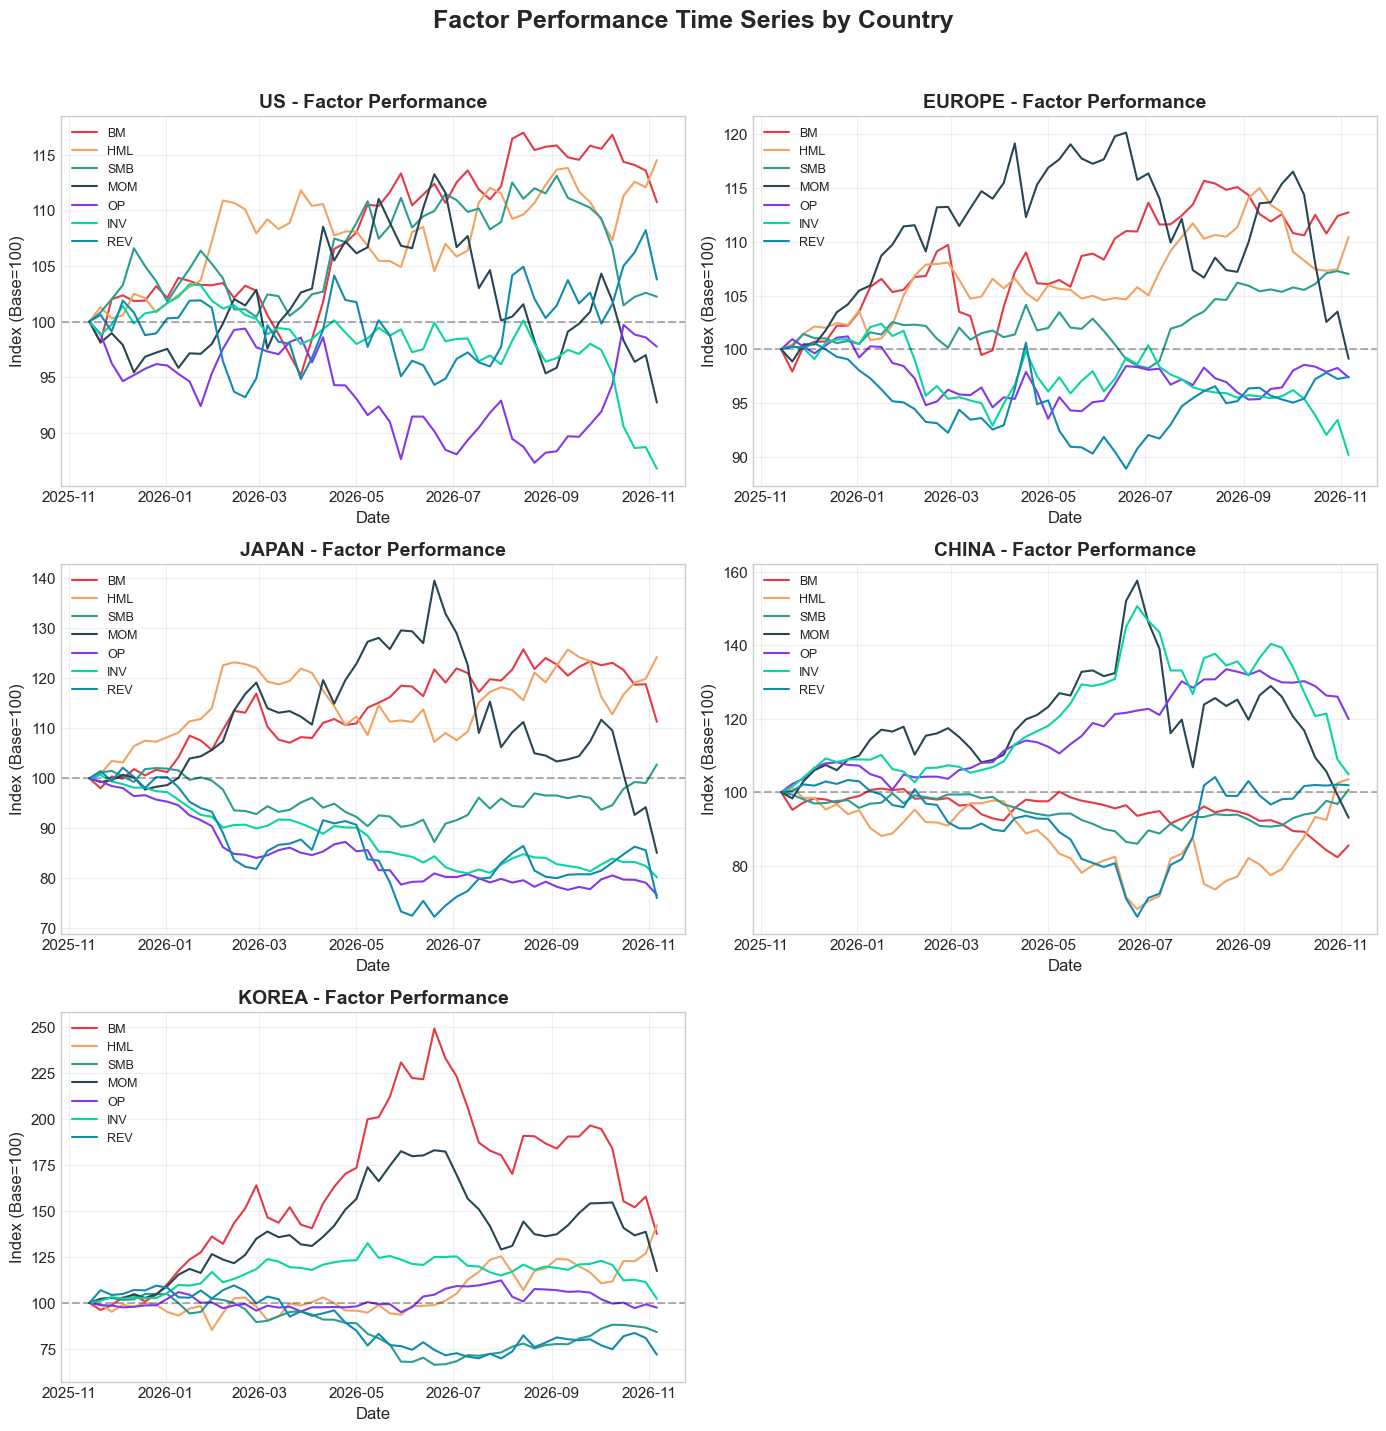

In [6]:
# Plot factor time series for each country
fig, axes = plt.subplots(3,2, figsize=(14, 14))
axes = axes.flatten()

for idx, country in enumerate(COUNTRIES):
    ax = axes[idx]
    factor_ts = data['factor_hs_clipped'][country]

    for col in factor_ts.columns:
        if col in FACTOR_COLORS:
            ax.plot(factor_ts.index, factor_ts[col], label=col,
                   color=FACTOR_COLORS.get(col, 'gray'), linewidth=1.5)

    ax.axhline(y=100, color='black', linestyle='--', alpha=0.3)
    ax.set_title(f'{country.upper()} - Factor Performance', fontsize=14, fontweight='bold')
    ax.set_xlabel('Date')
    ax.set_ylabel('Index (Base=100)')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.3)

# Hide the 6th subplot
axes[5].axis('off')

plt.suptitle('Factor Performance Time Series by Country', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [7]:
# Calculate factor statistics
def calculate_factor_stats(factor_ts, factor_hs):
    """Calculate comprehensive factor statistics"""
    returns = factor_ts.pct_change().dropna()

    stats = pd.DataFrame({
        'Total Return (%)': ((factor_ts.iloc[-1] / factor_ts.iloc[0]) - 1) * 100,
        'Ann. Return (%)': returns.mean() * 52 * 100,
        'Ann. Vol (%)': returns.std() * np.sqrt(52) * 100,
        'Sharpe Ratio': (returns.mean() * 52) / (returns.std() * np.sqrt(52)),
        'Max Drawdown (%)': ((factor_ts / factor_ts.cummax()) - 1).min() * 100,
        'Max Drawdown(total) (%)': ((factor_hs / factor_hs.cummax()) - 1).min() * 100,
        'Skewness': returns.skew(),
        'Kurtosis': returns.kurtosis()
    })
    return stats.round(3)

# Display factor stats for each country
for country in COUNTRIES:
    print(f"\n{'='*70}")
    print(f"{country.upper()} - FACTOR STATISTICS")
    print("="*70)
    stats = calculate_factor_stats(data['factor_hs_clipped'][country], clip_ts(data['factor_hs'][country], periods=52*5))
    display(stats.style.format('{:.1f}').background_gradient(cmap='RdYlGn', subset=['Sharpe Ratio'], axis=0))


US - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Max Drawdown(total) (%),Skewness,Kurtosis
BM,10.7,11.1,12.2,0.9,-8.4,-24.5,0.6,0.3
HML,14.5,14.6,12.1,1.2,-6.5,-17.8,0.3,-0.0
SMB,2.2,3.0,12.6,0.2,-10.3,-39.2,-0.1,0.6
MOM,-7.3,-6.2,17.6,-0.3,-18.1,-24.8,-0.2,-0.5
OP,-2.3,-1.4,14.0,-0.1,-12.7,-34.5,0.3,0.9
INV,-13.2,-14.0,10.0,-1.4,-16.1,-41.4,-0.7,1.4
REV,3.8,5.3,17.4,0.3,-9.4,-41.0,0.2,0.1



EUROPE - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Max Drawdown(total) (%),Skewness,Kurtosis
BM,12.7,13.0,12.3,1.1,-9.3,-19.8,-0.8,2.2
HML,10.5,10.5,9.0,1.2,-6.7,-13.9,-0.2,0.5
SMB,7.0,7.2,7.2,1.0,-5.7,-32.4,0.5,1.2
MOM,-0.9,0.5,16.6,0.0,-17.5,-21.3,-0.9,0.4
OP,-2.6,-2.4,8.4,-0.3,-7.6,-18.8,-0.1,-0.1
INV,-9.8,-10.0,10.5,-1.0,-11.9,-26.6,-0.1,-0.1
REV,-2.6,-2.0,11.4,-0.2,-11.7,-30.7,-0.2,3.4



JAPAN - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Max Drawdown(total) (%),Skewness,Kurtosis
BM,11.3,12.3,16.9,0.7,-11.5,-14.4,-0.5,0.4
HML,24.3,24.0,19.3,1.2,-12.9,-17.4,0.0,0.5
SMB,2.8,3.7,13.8,0.3,-14.5,-26.7,-0.0,0.3
MOM,-14.9,-11.8,30.5,-0.4,-39.0,-39.0,-0.4,0.6
OP,-23.3,-26.4,10.6,-2.5,-23.3,-34.6,-0.8,1.4
INV,-19.8,-22.0,8.7,-2.5,-20.3,-40.2,-0.0,0.2
REV,-23.9,-24.9,24.2,-1.0,-29.2,-47.2,-0.8,1.4



CHINA - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Max Drawdown(total) (%),Skewness,Kurtosis
BM,-14.5,-15.1,13.1,-1.1,-18.5,-36.9,0.0,0.1
HML,3.5,9.6,35.0,0.3,-32.6,-41.6,-0.2,2.5
SMB,0.7,1.4,12.4,0.1,-14.0,-32.1,0.8,0.5
MOM,-6.9,-0.0,38.6,-0.0,-41.0,-41.0,0.1,2.8
OP,19.9,19.4,13.1,1.5,-10.2,-39.1,-0.1,0.3
INV,4.8,8.0,25.5,0.3,-30.4,-43.6,-0.1,2.0
REV,1.9,6.6,31.3,0.2,-36.0,-61.7,0.9,3.8



KOREA - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Max Drawdown(total) (%),Skewness,Kurtosis
BM,37.5,43.3,46.7,0.9,-44.8,-44.8,-0.2,0.0
HML,42.3,42.7,36.8,1.2,-14.7,-31.4,-0.0,0.4
SMB,-15.9,-14.4,25.1,-0.6,-36.7,-68.1,-0.8,1.8
MOM,17.3,22.9,36.2,0.6,-35.9,-35.9,-0.6,1.1
OP,-2.6,-0.9,18.6,-0.1,-13.4,-24.4,-0.1,1.5
INV,2.2,4.4,21.1,0.2,-22.9,-25.3,-0.4,1.4
REV,-28.2,-27.4,35.6,-0.8,-36.2,-67.2,0.1,-0.0


### Factor Correlation Analysis

In [8]:
factor_returns = data['factor_hs_clipped']['korea'].pct_change().dropna()
corr = factor_returns.corr()
corr.to_clipboard()

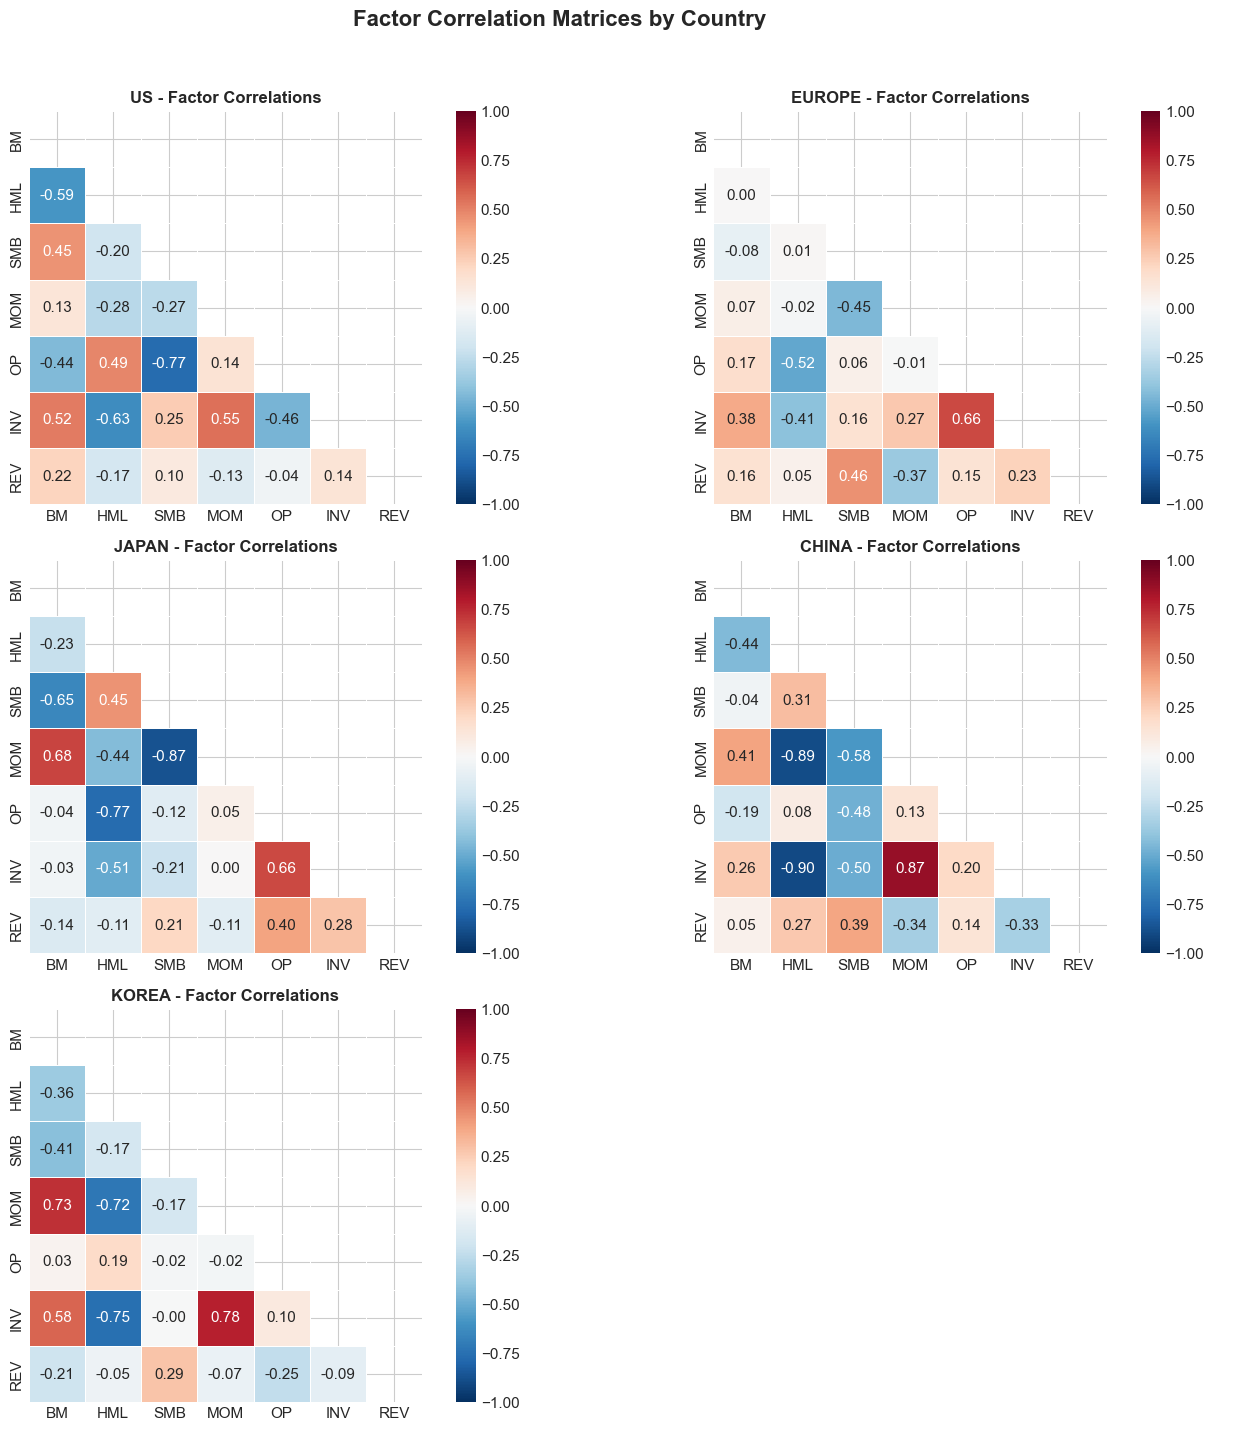

In [9]:
# Factor correlation matrices
fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for idx, country in enumerate(COUNTRIES):
    ax = axes[idx]
    factor_returns = data['factor_hs_clipped'][country].pct_change().dropna()
    corr = factor_returns.corr()

    mask = np.triu(np.ones_like(corr, dtype=bool))
    sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
                center=0, ax=ax, vmin=-1, vmax=1,
                square=True, linewidths=0.5)
    ax.set_title(f'{country.upper()} - Factor Correlations', fontsize=12, fontweight='bold')

axes[5].axis('off')
plt.suptitle('Factor Correlation Matrices by Country', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [10]:
# === Section 1 LLM: 과거 관찰 — 팩터 역사적 동인 ===
_hist_txt = f"HISTORICAL ANALYSIS — Factor Direction Summary (week ending approx. {datetime.date.today().isoformat()}\n\n"

for _c in COUNTRIES:
    _hs = data['factor_hs_clipped'][_c]
    _ret4   = (_hs.iloc[-1] / _hs.iloc[-5]  - 1) * 100 if len(_hs) >= 5  else pd.Series(dtype=float)
    _prior4 = (_hs.iloc[-5] / _hs.iloc[-9] - 1) * 100  if len(_hs) >= 9  else pd.Series(dtype=float)
    _accel  = (_ret4 - _prior4).dropna().sort_values(ascending=False)
    _top3   = list(_accel.head(3).index)
    _bot3   = list(_accel.tail(3).index)
    _hist_txt += f"{_c.upper()}: 가속 팩터={', '.join(_top3)} | 감속 팩터={', '.join(_bot3)}\n"

_hist_prompt = (
    "역할: 글로벌 퀀트 전략가. 이 섹션이 보고서의 첫 분석 단계입니다.\n\n"
    "제공된 국가별 팩터 가속/감속 방향 요약을 바탕으로 각 시장의 최신 거시경제 뉴스를 검색하십시오.\n\n"
    "검색 지시: 각 국가별로 '[국가명] 주식시장 팩터 [현재연월]' 쿼리로 최신 이벤트를 검색하십시오.\n\n"
    "출력 구조:\n"
    "1. 국가별 팩터 동향 관찰: 각 시장에서 팩터 흐름을 주도한 뉴스 이벤트/정책/테마. 팩터 방향은 괄호 안 간략 표기.\n"
    "2. 글로벌 공통 스타일 패턴: 여러 시장에서 동시에 관찰되는 스타일 로테이션과 배경 이벤트.\n"
    "3. 주목할 이상 신호: 글로벌 트렌드와 반하는 특이 시장과 그 이유.\n\n"
    "분량: A4 0.5페이지. 수치 나열 금지. 뉴스 내러티브 우선.\n"
    "※ 이 관찰은 다음 섹션(미래 신호)의 출발점으로 이어집니다."
)

show_explanation(_hist_txt, _hist_prompt, title="Section 1: 과거 관찰 — 팩터 역사적 동인 분석")


---
### 💬 Section 1: 과거 관찰 — 팩터 역사적 동인 분석

## 1. 국가별 팩터 동향 관찰

- **미국:** 중간선거 이후 데이터센터 인허가·전력수급 규제 강화 우려가 AI 인프라 투자 회수기간의 불확실성을 확대하면서, 고평가 AI·반도체 주도 모멘텀이 약화된 국면임. 이에 따라 이미 조정받은 종목과 저평가·소형주의 상대적 회복이 우세해진 것으로 판단됨 *(HML·REV·SMB↑ / INV·BM·MOM↓)*. ([apnews.com](https://apnews.com/article/d938f8e6ff42b3706e1d36e6245ec56b?utm_source=openai))

- **유럽:** 미국발 AI 리스크 전이에도 유가 하락과 정책 기대가 은행·유틸리티·헬스케어 등 전통 가치주로 자금을 이동시킨 흐름임. 기술주 중심 모멘텀 및 공격적 투자기업은 약화된 반면, 금융주 중심의 시장 민감도와 저평가·낙폭과대 회복이 부각됨 *(HML·BM·REV↑ / OP·INV·MOM↓)*. ([euronews.com](https://www.euronews.com/2026/11/09/trumps-midterm-defeat-europes-biggest-stock-winners-and-losers?utm_source=openai))

- **일본:** 글로벌 AI 매도 충격으로 Nikkei가 급락하며 대형 기술주 모멘텀과 시장 베타가 훼손됨. 다만 가치·소형·투자 팩터의 가속은 AI 대형주 집중 리스크를 회피하는 과정에서 일본 내 설비투자 및 비(非)메가캡 종목으로 상대적 관심이 이동했음을 시사함 *(HML·SMB·INV↑ / REV·BM·MOM↓)*. ([japantimes.co.jp](https://www.japantimes.co.jp/business/2026/11/06/markets/market-nov-6/?utm_source=openai))

- **중국:** 인민은행의 주식시장 유동성 공급과 당국의 대형 기술기업 자사주 매입 독려가 하방 방어 신호로 작용함. 그러나 이는 이익의 질보다 정책 수혜와 밸류에이션 정상화에 의존한 반등으로, 가치·소형·고베타 선호가 강화된 반면 수익성·투자·모멘텀은 둔화된 것으로 해석됨 *(HML·SMB·BM↑ / OP·INV·MOM↓)*. ([marketscreener.com](https://www.marketscreener.com/news/china-s-central-bank-taps-liquidity-tool-to-aid-struggling-stocks-ce785fd8de81f723?utm_source=openai))

- **한국:** 미국 선거 이후 AI 투자정책 불확실성이 국내 반도체 생태계로 즉시 전이되며 외국인 수급과 원화 변동성이 확대된 국면임. 이에 따라 반도체 중심 모멘텀·대형 성장주·고베타 노출은 후퇴하고, 실적 방어력이 있는 대형 가치주와 낙폭과대 종목이 상대 우위를 보인 것으로 판단됨 *(HML·OP·REV↑ / SMB·BM·MOM↓)*. ([biz.chosun.com](https://biz.chosun.com/en/en-finance/2026/11/05/ZC3NA7PABFB2JMR5DFYGZMEBGY/?utm_source=openai))

## 2. 글로벌 공통 스타일 패턴

핵심 공통 신호는 **AI CAPEX의 지속가능성 재평가에 따른 모멘텀 이탈 및 가치·리버설 전환**임. 미국발 데이터센터 규제·전력 인프라 불확실성이 글로벌 기술주 밸류에이션 압축으로 전파되었으며, 유가 하락과 금리 안정은 금융·방어주·저평가 업종의 상대매력을 높인 배경임. 투자확대 기업과 기존 승자군보다 현금흐름 가시성 및 낮은 기대가 반영된 종목을 선호하는 국면으로 판단됨. ([lseg.com](https://www.lseg.com/en/ftse-russell/market-insights/performance/november-2026?utm_source=openai))

## 3. 주목할 이상 신호

**일본의 INV 가속**은 글로벌 전반의 투자 팩터 감속과 상반되는 특이 신호임. 이는 단순 AI 투자 축소가 아니라, 대형 AI 밸류체인에서 일본 내 산업재·설비투자·비메가캡으로 투자 내러티브가 재배치되는 초기 징후일 수 있음. 반대로 중국의 고베타·소형주 강세는 실적 개선보다 유동성 및 시장안정화 정책에 의존한다는 점에서 지속성 검증이 필요한 신호로 판단됨.

---

---
## Section 2: 미래 신호 — 모델의 포워드 뷰

기대수익률(Expected Return)을 통해 모델이 예측하는 미래를 확인합니다.

### Market Expected Returns

MARKET-LEVEL ANALYSIS

⚠️  IMPORTANT: Market ER values are NOT directly comparable across countries
    because factor models have different scales/calibrations.

[1] MARKET ER - (z-score scales)
----------------------------------------------------------------------


,Weighted Mean ER (%)
US,-0.76
EUROPE,-0.42
JAPAN,-1.16
CHINA,-1.94
KOREA,-1.44



[2] CROSS-COUNTRY COMPARABLE METRICS
----------------------------------------------------------------------


,Market ER Percentile,Market ER Z-Score,% Stocks Positive ER,ER Dispersion (Q80-Q20),ER Sharpe (mean/std)
Country,,,,,
US,17.7,-0.76,44.5%,4.67,-0.04
EUROPE,26.9,-0.42,59.2%,1.57,0.03
JAPAN,12.0,-1.16,9.3%,3.29,-0.22
CHINA,3.3,-1.94,35.5%,2.57,-0.03
KOREA,5.2,-1.44,16.7%,2.68,-0.08



Interpretation Guide:
  • Market ER Percentile: Higher = More strong signal for the market relative to historical periods
  • % Stocks Positive ER: Higher = More bullish signal for the market
  • ER Sharpe: Higher = More consistent positive signal across stocks


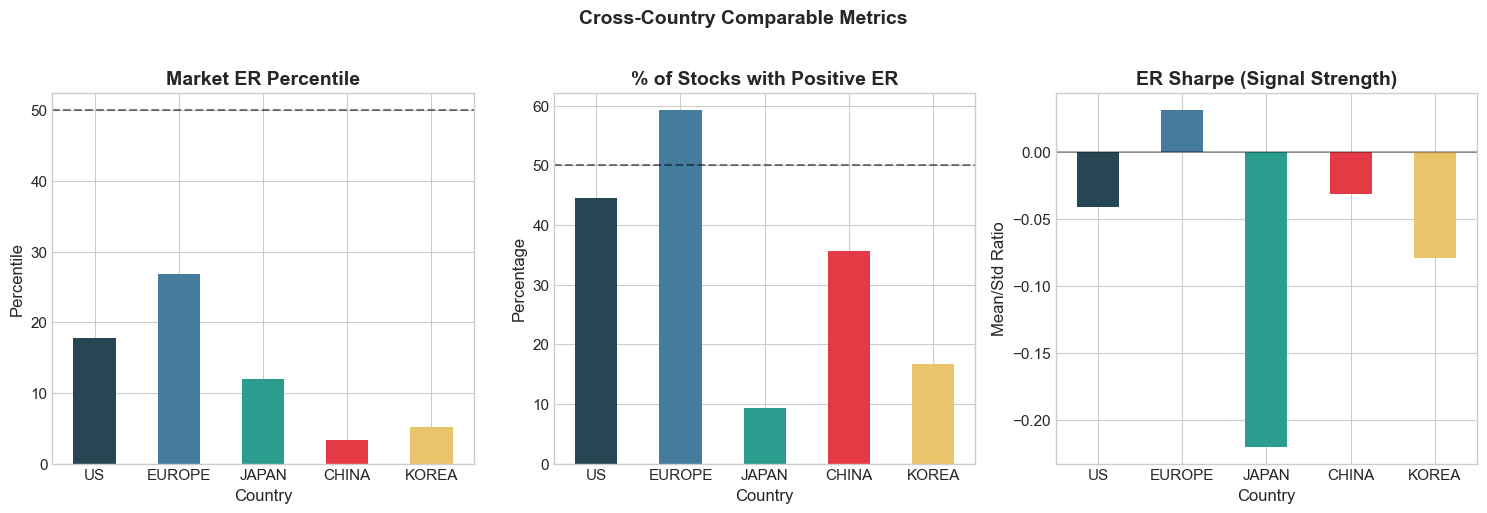

In [11]:
# Market-level expected returns comparison - WITH NORMALIZATION CONTEXT
print("="*70)
print("MARKET-LEVEL ANALYSIS")
print("="*70)
print("\n⚠️  IMPORTANT: Market ER values are NOT directly comparable across countries")
print("    because factor models have different scales/calibrations.\n")

# Raw market ERs
market_er = {}
for country in COUNTRIES:
    wmean = data['index_ER'][country]['ER_zscore'].iloc[0]
    market_er[country.upper()] = wmean

market_er_df = pd.DataFrame([market_er], index=['Weighted Mean ER (%)']).T

print("[1] MARKET ER - (z-score scales)")
print("-"*70)
display(market_er_df.style.format('{:.2f}'))

# Calculate comparable metrics using within-country distribution
print("\n[2] CROSS-COUNTRY COMPARABLE METRICS")
print("-"*70)

comparable_metrics = []
for country in COUNTRIES:
    total_stock_er = data['total_ER'][country]
    index_total_history_er = data['index_ts'][country]['index_ER']
    index_er = data['index_ER'][country]['wER'].iloc[0]

    # What percentile is the market ER within its own distribution?
    market_percentile = (index_er/100 > index_total_history_er).mean() * 100

    # Z-score of market ER within country
    market_zscore = data['index_ER'][country]['ER_zscore'].iloc[0]

    # Stock-wise
    er_values = total_stock_er['ER'].dropna()
    sh_values = total_stock_er['Sharpe'].dropna()

    # Percentage of stocks with positive ER
    pct_positive = (er_values > 0).mean() * 100

    # Spread between top and bottom quintile
    er_spread = er_values.quantile(0.8) - er_values.quantile(0.2)

    # Sharpe-like metric: mean ER / std ER
    er_sharpe = sh_values.mean()

    comparable_metrics.append({
        'Country': country.upper(),
        'Market ER Percentile': market_percentile,
        'Market ER Z-Score': market_zscore,
        '% Stocks Positive ER': pct_positive,
        'ER Dispersion (Q80-Q20)': er_spread,
        'ER Sharpe (mean/std)': er_sharpe
    })

comparable_df = pd.DataFrame(comparable_metrics).set_index('Country')
display(comparable_df.style.format({
    'Market ER Percentile': '{:.1f}',
    'Market ER Z-Score': '{:.2f}',
    '% Stocks Positive ER': '{:.1f}%',
    'ER Dispersion (Q80-Q20)': '{:.2f}',
    'ER Sharpe (mean/std)': '{:.2f}'
}).background_gradient(cmap='RdYlGn', axis=0))

print("\nInterpretation Guide:")
print("  • Market ER Percentile: Higher = More strong signal for the market relative to historical periods")
print("  • % Stocks Positive ER: Higher = More bullish signal for the market")
print("  • ER Sharpe: Higher = More consistent positive signal across stocks")

# Bar chart of comparable metrics
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot 1: Market Percentile
ax = axes[0]
colors = [COUNTRY_COLORS[c.lower()] for c in comparable_df.index]
comparable_df['Market ER Percentile'].plot(kind='bar', ax=ax, color=colors)
ax.set_title('Market ER Percentile', fontweight='bold')
ax.set_ylabel('Percentile')
ax.axhline(y=50, color='black', linestyle='--', alpha=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

# Plot 2: % Positive ER
ax = axes[1]
comparable_df['% Stocks Positive ER'].plot(kind='bar', ax=ax, color=colors)
ax.set_title('% of Stocks with Positive ER', fontweight='bold')
ax.set_ylabel('Percentage')
ax.axhline(y=50, color='black', linestyle='--', alpha=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

# Plot 3: ER Sharpe
ax = axes[2]
comparable_df['ER Sharpe (mean/std)'].plot(kind='bar', ax=ax, color=colors)
ax.set_title('ER Sharpe (Signal Strength)', fontweight='bold')
ax.set_ylabel('Mean/Std Ratio')
ax.axhline(y=0, color='black', linestyle='-', alpha=0.3)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

plt.suptitle('Cross-Country Comparable Metrics', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Factor Expected Returns

In [12]:
# Create factor returns comparison table - RAW and NORMALIZED
print("="*70)
print("FACTOR RETURNS BY COUNTRY")
print("="*70)
print("    Use Z-Score for valid cross-country comparisons.\n")

# Z-Score normalized (within each country)
factor_zscore_df = pd.DataFrame()
for country in COUNTRIES:
    fr = data['factor_ER'][country]['ER_zscore']
    factor_zscore_df[country.upper()] = fr
factor_zscore_df = factor_zscore_df.T

print("\n[2] Z-SCORE NORMALIZED - Comparable across countries (0 = country average)")
print("-"*70)
display(factor_zscore_df.style.format('{:.2f}').background_gradient(cmap='RdYlGn', axis=None))

# Cross-country factor comparison using z-scores
print("\n[4] CROSS-COUNTRY FACTOR STRENGTH (Z-Score Average)")
print("-"*70)
print("Which factors are consistently strong/weak across all markets:")
factor_strength = factor_zscore_df.mean().sort_values(ascending=False)
for factor, zscore in factor_strength.items():
    strength = "STRONG ↑" if zscore > 0.5 else ("WEAK ↓" if zscore < -0.5 else "NEUTRAL →")
    bar = "█" * int(abs(zscore) * 10)
    print(f"  {factor:5}: {zscore:+.2f} {strength} {bar}")

FACTOR RETURNS BY COUNTRY
    Use Z-Score for valid cross-country comparisons.


[2] Z-SCORE NORMALIZED - Comparable across countries (0 = country average)
----------------------------------------------------------------------


,BM,HML,INV,MOM,OP,SMB
US,-0.77,-1.33,-0.95,-2.44,-0.28,0.44
EUROPE,-0.42,-1.01,-0.98,-3.81,-0.38,0.53
JAPAN,-1.18,-1.84,-2.39,-2.30,-2.10,2.24
CHINA,-1.93,0.65,-4.43,-2.75,-3.86,0.77
KOREA,-1.51,-1.75,-1.63,-0.85,-0.63,-0.52



[4] CROSS-COUNTRY FACTOR STRENGTH (Z-Score Average)
----------------------------------------------------------------------
Which factors are consistently strong/weak across all markets:
  SMB  : +0.69 STRONG ↑ ██████
  HML  : -1.06 WEAK ↓ ██████████
  BM   : -1.16 WEAK ↓ ███████████
  OP   : -1.45 WEAK ↓ ██████████████
  INV  : -2.08 WEAK ↓ ████████████████████
  MOM  : -2.43 WEAK ↓ ████████████████████████


### Factor Premium Comparison

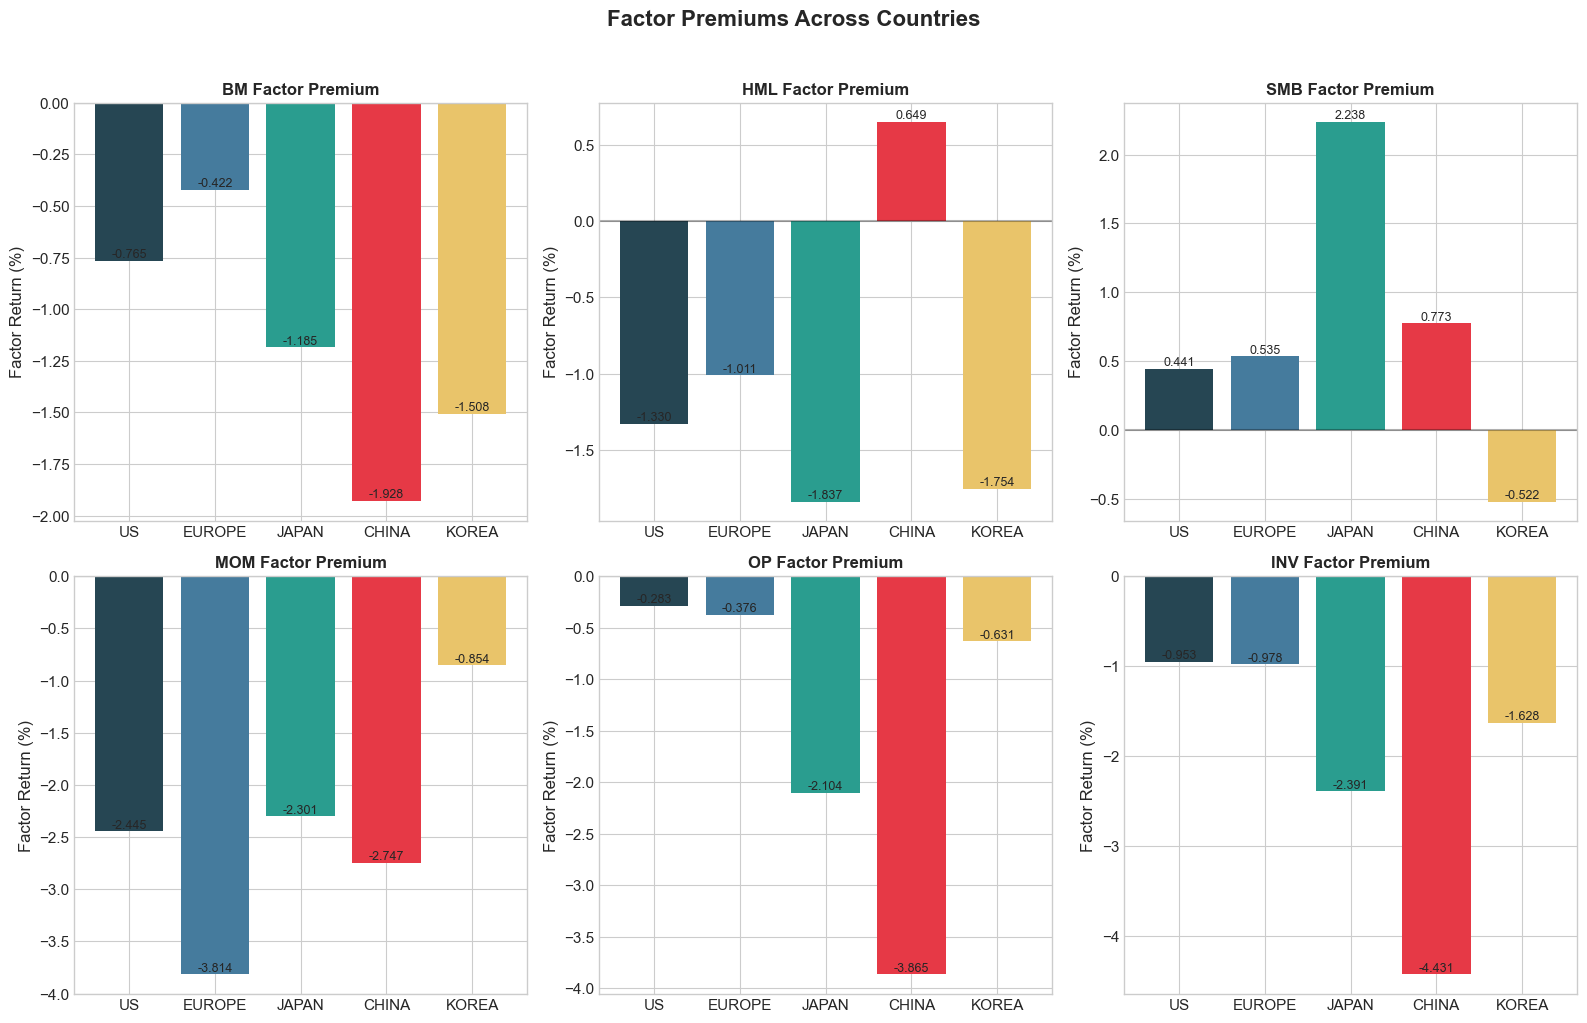

In [13]:
# Factor premium comparison across countries
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

factors = ['BM', 'HML', 'SMB', 'MOM', 'OP', 'INV']

for idx, factor in enumerate(factors):
    ax = axes[idx]
    factor_vals = []

    for country in COUNTRIES:
        fr = data['factor_ER'][country]['ER_zscore']
        if factor in fr.index:
            factor_vals.append(fr.loc[factor])
        else:
            factor_vals.append(0)

    colors = [COUNTRY_COLORS[c] for c in COUNTRIES]
    bars = ax.bar([c.upper() for c in COUNTRIES], factor_vals, color=colors)
    ax.axhline(y=0, color='black', linestyle='-', alpha=0.3)
    ax.set_title(f'{factor} Factor Premium', fontsize=12, fontweight='bold')
    ax.set_ylabel('Factor Return (%)')

    # Add value labels
    for bar, val in zip(bars, factor_vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
                f'{val:.3f}', ha='center', va='bottom', fontsize=9)

plt.suptitle('Factor Premiums Across Countries', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Sector Expected Returns

In [14]:
# Sector Expected Returns comparison - RAW and NORMALIZED
print("="*90)
print("SECTOR EXPECTED RETURNS BY COUNTRY")
print("="*90)
print("\n⚠️  NOTE: Raw ER values have different scales across countries.")
print("    Use Z-Score for valid cross-country sector comparisons.\n")

# Z-Score normalized sector ERs
sector_zscore_comparison = pd.DataFrame()
for country in COUNTRIES:
    ind_er = data['sector_ER'][country].copy()
    ind_er = ind_er.set_index('Sector')
    sector_zscore_comparison[country.upper()] = ind_er['ER_zscore']

print("\n[2] Z-SCORE NORMALIZED - Comparable (0 = average sector in country)")
print("-"*70)
display(sector_zscore_comparison.style.format('{:.2f}').background_gradient(cmap='RdYlGn', axis=None))

# Cross-country sector analysis
print("\n[4] GLOBAL SECTOR ATTRACTIVENESS (Average Z-Score across countries)")
print("-"*70)
sector_global_strength = sector_zscore_comparison.mean(axis=1).sort_values(ascending=False)
for sector, zscore in sector_global_strength.items():
    strength = "OVERWEIGHT" if zscore > 0.3 else ("UNDERWEIGHT" if zscore < -0.3 else "NEUTRAL")
    bar = "█" * int(abs(zscore) * 10)
    print(f"  {str(sector):25}: {zscore:+.2f} {strength} {bar}")

SECTOR EXPECTED RETURNS BY COUNTRY

⚠️  NOTE: Raw ER values have different scales across countries.
    Use Z-Score for valid cross-country sector comparisons.


[2] Z-SCORE NORMALIZED - Comparable (0 = average sector in country)
----------------------------------------------------------------------


,US,EUROPE,JAPAN,CHINA,KOREA
Sector,,,,,
Energy,-0.81,0.01,-0.82,-1.66,-0.55
Materials,-0.29,-0.34,-1.19,-2.63,-0.96
Industrials,-0.90,-0.74,-1.22,-1.94,-1.20
Consumer Discretionary,-0.37,-0.45,-0.89,-2.10,-1.08
Consumer Staples,-0.45,0.40,-0.91,-0.60,-0.61
Health Care,0.26,0.46,-0.98,-0.77,-1.35
Financials,-0.30,-0.38,-0.83,-0.53,-0.45
Information Technology,-0.98,-1.02,-1.62,-2.11,-1.52
Communication Services,-0.79,-0.25,-1.10,-1.35,-0.82



[4] GLOBAL SECTOR ATTRACTIVENESS (Average Z-Score across countries)
----------------------------------------------------------------------
  Real Estate              : -0.28 NEUTRAL ██
  Consumer Staples         : -0.43 UNDERWEIGHT ████
  Health Care              : -0.48 UNDERWEIGHT ████
  Financials               : -0.50 UNDERWEIGHT ████
  Utilities                : -0.71 UNDERWEIGHT ███████
  Energy                   : -0.77 UNDERWEIGHT ███████
  Communication Services   : -0.86 UNDERWEIGHT ████████
  Consumer Discretionary   : -0.98 UNDERWEIGHT █████████
  Materials                : -1.08 UNDERWEIGHT ██████████
  Industrials              : -1.20 UNDERWEIGHT ███████████
  Information Technology   : -1.45 UNDERWEIGHT ██████████████


In [15]:
# === Section 2 LLM: 미래 신호 — 모델의 포워드 뷰 ===
_forward_txt = f"FORWARD SIGNALS — Factor & Market Expected Returns (as of {datetime.date.today().isoformat()}\n\n"

_factors_list = ['BM', 'HML', 'SMB', 'MOM', 'OP', 'INV']

_forward_txt += "글로벌 팩터 기대수익률 방향 (4주 기준, 국가별 상승↑/하락↓):\n"
for _f in _factors_list:
    _col = f"{_f}_ER"
    _dirs = []
    for _c in COUNTRIES:
        _fts = data['factor_ts'][_c]
        if _col in _fts.columns and len(_fts) >= 5:
            _chg = float(_fts[_col].iloc[-1]) - float(_fts[_col].iloc[-5])
            _dirs.append(f"{_c.upper()}:{'↑' if _chg > 0 else '↓'}")
        else:
            _dirs.append(f"{_c.upper()}:?")
    _up = sum(1 for d in _dirs if '↑' in d)
    _consensus = "글로벌 상승" if _up >= 4 else ("글로벌 하락" if _up <= 1 else "혼조")
    _forward_txt += f"  {_f}: {' '.join(_dirs)} → {_consensus}\n"

_forward_txt += "\n국가별 시장 ER 상황:\n"
for _c in COUNTRIES:
    _mz = data['index_ER'][_c]['ER_zscore'].iloc[0]
    _top = data['factor_ER'][_c]['ER_zscore'].idxmax()
    _bot = data['factor_ER'][_c]['ER_zscore'].idxmin()
    _forward_txt += f"  {_c.upper()}: 시장ER z={_mz:.2f} | 최강팩터={_top} | 최약팩터={_bot}\n"

_forward_txt += "\n글로벌 섹터 매력도 (상위3/하위3):\n"
_sec_z = {}
for _c in COUNTRIES:
    _s_df = data['sector_ER'][_c].copy()
    if 'Sector' not in _s_df.columns and 'sector' in _s_df.columns:
        _s_df['Sector'] = _s_df['sector'].astype(str).map(SECTOR_NAMES)
    for _, _row in _s_df.iterrows():
        _sec = _row.get('Sector', '')
        if _sec and pd.notna(_sec):
            _sec_z.setdefault(str(_sec), []).append(_row.get('ER_zscore', 0))
_sec_avg = {s: sum(v)/len(v) for s, v in _sec_z.items() if v}
_sec_sorted = sorted(_sec_avg.items(), key=lambda x: x[1], reverse=True)
_forward_txt += "  상위: " + ", ".join(s for s, _ in _sec_sorted[:3]) + "\n"
_forward_txt += "  하위: " + ", ".join(s for s, _ in _sec_sorted[-3:]) + "\n"

_forward_prompt = (
    "[이전 섹션에서 확인한 팩터 동향과 뉴스 드라이버를 이어받아 분석합니다.]\n\n"
    "역할: 글로벌 퀀트 전략가. 제공되는 데이터는 '기대수익률(Expected Return)' — "
    "모델이 예측하는 미래 팩터·시장·섹터 수익률입니다.\n\n"
    "검색 지시: 각 국가별로 '[국가명] 경제 전망 [현재연월]' 쿼리로 최신 포워드 뷰 뉴스를 검색하십시오.\n\n"
    "출력 구조:\n"
    "1. 과거 추세와의 연속성/단절: 앞서 관찰한 팩터 모멘텀이 기대수익률에서도 지속되는가, "
    "아니면 모델이 반전을 예고하는가? (국가별 비교)\n"
    "2. 국가별 미래 포지셔닝: 기대수익률 기준 가장 매력적/비매력적인 시장과 그 이유 (뉴스 근거 포함).\n"
    "3. 주목할 섹터 방향: 기대수익률 상위 섹터가 강세인 배경 이벤트와 그 지속 가능성.\n\n"
    "분량: A4 0.5페이지. 수치 나열 금지.\n"
    "※ 다음 섹션에서 이 분석을 바탕으로 글로벌 통합 테제를 선언합니다."
)

show_explanation(_forward_txt, _forward_prompt, title="Section 2: 미래 신호 — 모델의 포워드 뷰 분석")


---
### 💬 Section 2: 미래 신호 — 모델의 포워드 뷰 분석

## 1. 과거 추세와의 연속성/단절

**핵심 판단은 기존의 ‘가치·리버설’ 국면이 유지되되, 향후 4주에는 AI 투자 회수율 재평가 이후의 선택적 재위험선호가 병행되는 전환 국면이라는 점임.** 미국은 직전 가치·소형·리버설 우위에서 벗어나 수익성 및 투자 팩터의 반등을 예고하나, 모멘텀 약세는 지속되는 구조임. 이는 미국 경제의 내수와 AI 관련 설비투자 자체는 견조하지만, 중간선거 이후 데이터센터 규제와 AI 인프라 CAPEX의 수익성에 대한 의문이 메가캡 기술주의 추세 복귀를 제약하기 때문임. ([usbank.com](https://www.usbank.com/corporate-and-commercial-banking/insights/economy/outlook/monthly.html?utm_source=openai))

유럽은 가치·베타·리버설 강세가 소형주 및 모멘텀으로 확장되는 가장 정합적인 연속성 국면임. 다만 에너지 충격 이후의 취약한 성장과 낮은 생산성은 공격적 투자 팩터의 지속성을 제한할 전망임. ([imf.org](https://www.imf.org/en/publications/reo/eu/issues/2026/10/16/regional-economic-outlook-europe-october-2026?utm_source=openai)) 일본은 가치·소형주 선호가 유지되지만, 직전의 투자 팩터 강세는 약화되고 모멘텀 회복이 예상됨. 미국 정치 충격에 따른 주가 조정과 금리인상 기대 후퇴가 대형 성장주 집중을 완화하는 한편, 내수·중소형주로의 재배치를 유도하는 흐름으로 판단됨. ([mufgresearch.com](https://www.mufgresearch.com/rates/japan-economic-financial-weekly-9-november-2026/?utm_source=openai)) 중국은 소형주 우위가 후퇴하는 대신 가치·베타·수익성·투자·모멘텀의 반등을 예고하나, 이는 정책·유동성 의존적 반등이라는 성격이 강함. ([bbvaresearch.com](https://www.bbvaresearch.com/en/publicaciones/china-economic-outlook-september-2026/?utm_source=openai)) 한국은 가치·수익성·리버설 중심의 방어적 국면에서 베타·모멘텀·투자 팩터 회복으로 이동하나, 반도체 사이클 및 AI 정책 불확실성으로 인해 추세적 강세 전환으로 단정하기는 이른 상황임. ([english.mofe.go.kr](https://english.mofe.go.kr/pc/selectTbPressCenterDtl.do?boardCd=N0001&seq=6522&utm_source=openai))

## 2. 국가별 미래 포지셔닝

시장 기대수익률 기준으로는 **미국을 상대 최선호, 유럽을 차선호, 일본·한국을 중립 이하, 중국을 최저선호**로 제시함. 미국은 물가와 장기금리 부담에도 소비와 AI 관련 기업투자가 경제를 지지하고 있어 상대적 방어력이 가장 높음. 다만 AI 규제 및 CAPEX 수익성 논란으로 시장 전체보다는 수익성 기반의 선별 접근이 필요함. ([usbank.com](https://www.usbank.com/corporate-and-commercial-banking/insights/economy/outlook/monthly.html?utm_source=openai)) 유럽은 독일 제조업 회복과 설비투자 개선 기대가 가치·소형주에 우호적이나, 에너지 및 구조적 성장 제약이 상단을 제한함. ([mufgresearch.com](https://www.mufgresearch.com/macro/european-macro-weekly-6-november-2026/?utm_source=openai)) 중국은 수출과 첨단제조가 버티고 있음에도 부동산·소비·민간 신용수요 부진이 지속되어, 정책 반등을 전략적 비중확대의 근거로 보기에는 불충분함. ([bbvaresearch.com](https://www.bbvaresearch.com/en/publicaciones/china-economic-outlook-september-2026/?utm_source=openai))

## 3. 주목할 섹터 방향

상위 기대수익률은 **부동산·필수소비재·헬스케어**로, AI 인프라 투자 조정과 정치·금리 불확실성 아래서 방어적 현금흐름을 선호하는 자금 이동을 반영함. 특히 헬스케어는 미국의 공공의료 재원 및 보조금 정상화 기대가 병원·서비스 기업에 우호적으로 작용하고 있으며, 필수소비재 역시 위험자산 축소 국면의 피난처 역할을 수행 중임. ([apnews.com](https://apnews.com/article/4ac9a6a3c35aeec37374fc8083bf9395?utm_source=openai)) 부동산의 강세는 금리인상 경로 둔화 기대에 기댄 전술적 신호로 해석해야 하며, 높은 모기지금리와 주택가격 부담이 지속되는 한 구조적 강세로 확대 해석하기는 어려움. ([apnews.com](https://apnews.com/article/4ac9a6a3c35aeec37374fc8083bf9395?utm_source=openai)) 반대로 정보기술·산업재·소재는 AI CAPEX 재평가, 설비투자 불확실성 및 경기민감 수요 둔화 우려의 직접적 부담권역임. 따라서 다음 섹션의 글로벌 통합 테제는 **‘기술주 추격 회피, 방어주 중심의 가치 노출 유지, 정책·실적 확인 시 소형주와 투자 팩터를 선택적으로 재편입’**으로 설정하는 것이 타당함.

---

---
## Section 3: 글로벌 테제 합성

과거 관찰과 미래 신호를 통합하여 하나의 시장 테제를 도출합니다.

In [16]:
# === Section 3 LLM: 글로벌 테제 합성 (NEW) ===
_thesis_txt = (
    f"GLOBAL THESIS SYNTHESIS (as of {datetime.date.today().isoformat()}\n\n"
    "앞선 두 섹션에서 다음이 확인됨:\n"
    "  • Section 1: 국가별 팩터 가속/감속 동향 및 뉴스 드라이버\n"
    "  • Section 2: 팩터·시장·섹터 기대수익률의 포워드 신호\n"
    "이 두 관찰을 통합하여 글로벌 투자 테제를 도출하십시오.\n"
)

_thesis_prompt = (
    "[지금까지 두 섹션의 분석 — 과거 팩터 행동 관찰과 미래 기대수익률 신호 — 을 통합합니다.]\n\n"
    "역할: 수석 투자전략가(CIO). 이 섹션에서 공식 시장 테제를 선언합니다.\n\n"
    "출력 구조:\n"
    "1. 글로벌 시장 테제 (1-2문장): "
    "현재 글로벌 시장은 [X 국면]에 있으며, [Y 팩터/섹터/스타일]이 유리한 환경이다. "
    "핵심 드라이버는 [Z 이벤트/정책/매크로]이다.\n"
    "2. 지역별 테제 강도: 이 테제가 가장 강하게 적용되는 시장 vs. 예외·이탈 시장 (이유 포함).\n"
    "3. 테제 유효 기간과 무효화 조건: 어떤 이벤트/지표가 발생하면 이 테제를 수정해야 하는가.\n\n"
    "분량: A4 0.5페이지.\n"
    "이 섹션은 보고서 전체의 중심 주장입니다 — 명확하고 단호하게 서술할 것. 수치 나열 금지."
)

show_explanation(_thesis_txt, _thesis_prompt, title="Section 3: 글로벌 테제 합성")


---
### 💬 Section 3: 글로벌 테제 합성

## 1. 글로벌 시장 테제

**글로벌 주식시장은 ‘AI 주도 고평가 성장주의 재평가’와 ‘방어적 가치·현금흐름 자산으로의 로테이션’ 국면에 진입한 것으로 판단함.** 향후 수 주간은 저평가 가치주, 실적 가시성이 높은 방어 업종, 금리 민감 자산 및 선별적 소형주가 상대 우위에 있으며, 정보기술·산업재·소재의 추세 추종은 억제할 필요가 있음. 핵심 드라이버는 미국 중간선거 이후 AI 데이터센터 인허가·비용 부담에 대한 재평가, 높은 장기금리와 에너지·인플레이션 불확실성, 그리고 성장의 국가·기업 간 편차 확대임. ([cws-main-ndc.jpmorgan.com](https://cws-main-ndc.jpmorgan.com/insights/global-research/current-events/us-midterms-markets?utm_source=openai))

## 2. 지역별 테제 강도

**테제가 가장 강하게 적용되는 시장은 유럽 및 미국임.** 유럽은 에너지 충격에도 성장세가 취약한 만큼 공격적 설비투자보다 금융·필수소비재·헬스케어 등 가치·방어 스타일의 상대매력이 높음. 다만 독일의 경기 모멘텀과 설비투자 개선 조짐은 소형 가치주에 대한 제한적 상방을 제공함. 미국 역시 견조한 소비와 AI 관련 기업투자가 경기 하방을 방어하지만, 인플레이션과 자금조달비용이 높은 상태여서 메가캡 AI 추격보다 수익성·가격결정력 중심의 선별이 적절함. ([imf.org](https://www.imf.org/en/publications/reo/eu/issues/2026/10/16/regional-economic-outlook-europe-october-2026?utm_source=openai))

**일본은 부분적 예외 시장임.** 내수, 임금, 기업 설비투자가 견조하고 일본은행의 추가 정상화 가능성이 존재하여 가치·소형주 우위는 유효하나, 금리 상승과 글로벌 위험회피가 시장 베타와 공격적 투자 팩터에는 제약 요인임. ([externalcrewnet.vanguard.com](https://externalcrewnet.vanguard.com/content/corporatesite/us/en/corp/vemo/vemo-japan.html?utm_source=openai))

**중국은 정책 반등의 수혜 시장이지만, 본 테제의 가장 중요한 이탈·경계 대상임.** 통화당국의 자본시장 지원과 유동성 공급은 단기 베타·모멘텀 반등을 가능하게 하나, 내수·부동산·민간투자 부진이 지속되는 한 광범위한 위험자산 재평가로 보기 어려움. 중국은 고배당 방어주와 수출·첨단제조 정책 수혜주로 한정해야 함. ([scmp.com](https://www.scmp.com/business/china-business/article/3373166/pboc-pledges-support-stocks-chinas-market-slide-defies-rescue-efforts?pgtype=live&utm_source=openai))

한국은 반도체 호황이 성장 방어막을 제공하나, AI 투자 사이클 및 대외 정책 변화에 대한 민감도가 높음. 따라서 시장 전체 베타 확대보다 이익 방어력이 검증된 대형 가치·수익성 종목 중심 접근을 권고함. ([bok.or.kr](https://www.bok.or.kr/eng/bbs/E0000634/view.do?menuNo=400423&nttId=11064205&utm_source=openai))

## 3. 테제 유효 기간과 무효화 조건

본 테제의 유효 기간은 **연말 및 향후 1~2개월**로 설정함. 무효화 조건은 세 가지임. 첫째, AI 인프라 투자기업의 실적과 신규 수주가 비용·규제 우려를 상회하며 기술주 이익 전망을 재상향하는 경우임. 둘째, 에너지 가격 안정과 물가 둔화가 확인되어 주요 중앙은행의 완화 기대가 재강화되는 경우임. 셋째, 중국이 부동산·가계소비·민간신용을 실질적으로 회복시키는 대규모 재정정책을 발표하는 경우임. 이 경우 현재의 방어적 가치 편향을 축소하고, 정보기술·산업재 및 중국·한국의 경기민감 베타를 재확대해야 함. ([morganstanley.com](https://www.morganstanley.com/insights/articles/2026-us-midterm-election-results-market-impact?utm_source=openai))

---

---
## Section 4: 섹터·팩터 함의

확정된 테제를 기반으로 섹터 배분 방향을 도출합니다.

### Sector Factor Exposures

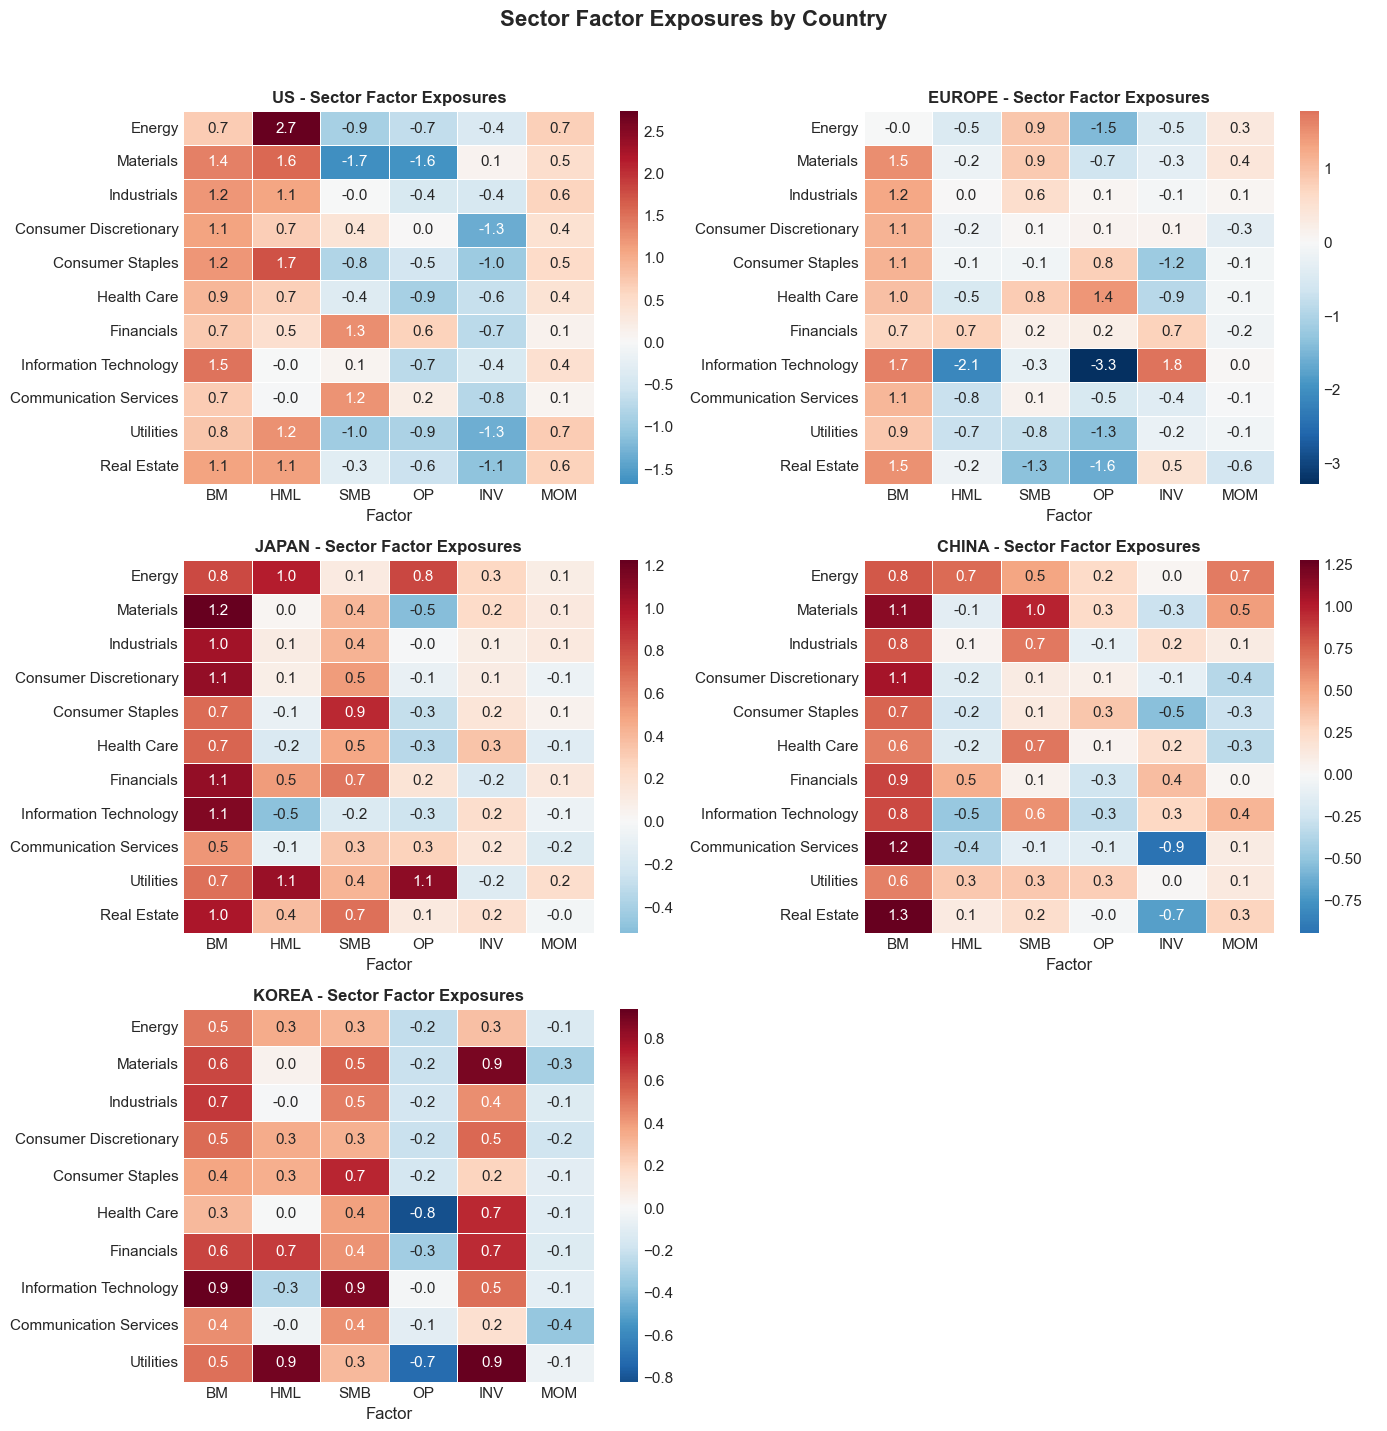

In [17]:
# Sector factor exposure heatmaps
factor_cols = ['beta_bm', 'beta_hml', 'beta_smb', 'beta_op', 'beta_inv', 'beta_mom']

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for idx, country in enumerate(COUNTRIES):
    ax = axes[idx]
    ind_er = data['sector_ER'][country].copy()

    # Get sector names as index
    if 'Sector' in ind_er.columns:
        ind_er = ind_er.set_index('Sector')
    elif 'industry' in ind_er.columns:
        ind_er['Sector'] = ind_er['industry'].astype(str).map(SECTOR_NAMES)
        ind_er = ind_er.set_index('Sector')

    # Get available factor columns
    available_factors = [col for col in factor_cols if col in ind_er.columns]

    if available_factors:
        plot_data = ind_er[available_factors].dropna(how='all')
        plot_data.columns = [c.replace('beta_', '').upper() for c in plot_data.columns]

        sns.heatmap(plot_data, annot=True, fmt='.1f', cmap='RdBu_r',
                    center=0, ax=ax, linewidths=0.5)
        ax.set_title(f'{country.upper()} - Sector Factor Exposures', fontsize=12, fontweight='bold')
        ax.set_xlabel('Factor')
        ax.set_ylabel('')
    else:
        ax.text(0.5, 0.5, 'No factor data available', ha='center', va='center')
        ax.set_title(f'{country.upper()}')

axes[5].axis('off')
plt.suptitle('Sector Factor Exposures by Country', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [18]:
from itertools import islice

# === Section 4 LLM: 섹터·팩터 함의 ===
_beta_cols_map = {'BM': 'beta_bm', 'HML': 'beta_hml', 'SMB': 'beta_smb',
                  'OP': 'beta_op', 'INV': 'beta_inv', 'MOM': 'beta_mom'}

_sector_impl_txt = "FACTOR-SECTOR ALIGNMENT ANALYSIS\n\n"

_sector_impl_txt += "국가별/섹터별 팩터 정렬 점수 상세:\n"
for _c in COUNTRIES:

    _f_zscores = {}
    for _f in ['BM', 'HML', 'SMB', 'MOM', 'OP', 'INV']:
        _vals = data['factor_ER'][_c]['ER_zscore'].get(_f, 0)
        _f_zscores[_f] = _vals
    _sorted_f = dict(sorted(_f_zscores.items(), key=lambda item: item[1], reverse=True))

    _strong = dict(islice(_sorted_f.items(), 2))
    _weak = dict(islice(reversed(_sorted_f.items()), 2))
    _sector_impl_txt += f"현재 강세 팩터: {', '.join(_strong) if _strong else '없음'}\n"
    _sector_impl_txt += f"현재 약세 팩터: {', '.join(_weak) if _weak else '없음'}\n\n"


    _sector_impl_txt += f"  [{_c.upper()}]\n"
    _sec_df = data['industry_ER'][_c].copy()
    if 'Sector' in _sec_df.columns:
        _sec_df = _sec_df.set_index('Sector')
    elif 'industry' in _sec_df.columns:
        _sec_df = _sec_df.set_index('industry')
    for _sec in _sec_df.index:
        _factor_details = []
        for _f, _bcol in _beta_cols_map.items():
            if _bcol in _sec_df.columns and _f in _f_zscores:
                _bval = _sec_df.loc[_sec, _bcol]
                _factor_details.append(f"{_f}:{_bval:.2f}")
        _sector_impl_txt += f"    - {_sec}: {', '.join(_factor_details)}\n"
    _sector_impl_txt += "\n"

_sector_impl_prompt = (
    "[확정된 글로벌 테제를 기반으로 섹터 배분 함의를 도출합니다.]\n\n"
    "역할: 글로벌 팩터-섹터 전략가.\n\n"
    "수혜 섹터 = 강세 팩터에 높은 베타 노출 (팩터 프리미엄 수령), "
    "역풍 섹터 = 약세 팩터에 높은 베타 노출 (팩터 드래그).\n\n"
    "출력 구조:\n"
    "1. 테제 수혜 섹터 (표): 국가 | 섹터 | 수혜 근거 (팩터-섹터 정렬 + 뉴스 촉매) — 국가별 3개씩\n"
    "2. 테제 역풍 섹터 (표): 국가 | 섹터 | 역풍 근거 — 국가별 3개씩\n"
    "3. 글로벌 오버웨이트/언더웨이트 권고: 테제에 기반한 섹터 배분 방향 요약.\n\n"
    "수치 나열 금지. 섹터 배분 관점의 핵심만 서술.\n"
    "※ 다음 섹션에서 이 섹터 방향을 구체적인 종목으로 연결합니다."
)

show_explanation(_sector_impl_txt, _sector_impl_prompt,
                 title="Section 4: 섹터·팩터 함의 — 테제 기반 섹터 배분", use_search=True)


---
### 💬 Section 4: 섹터·팩터 함의 — 테제 기반 섹터 배분

## 1. 테제 수혜 섹터

| 국가 | 섹터 | 수혜 근거: 팩터–섹터 정렬 및 뉴스 촉매 |
|---|---|---|
| 미국 | 소비자금융 | 소형주·수익성 노출이 높고 가치·모멘텀 민감도는 낮아 현 국면에 정렬됨. 유가 하락이 가계의 비용 부담과 위험선호를 일부 완화하는 환경도 소비·신용 관련 업종에 우호적임. ([apnews.com](https://apnews.com/article/stocks-markets-ai-trump-oil-d938f8e6ff42b3706e1d36e6245ec56b)) |
| 미국 | 운송 인프라 | 소형·수익성 팩터 수혜가 뚜렷하고 모멘텀 의존도가 낮음. AI CAPEX 재평가 국면에서 데이터센터·반도체 중심 투자보다 실물 인프라 및 안정적 운영자산으로 자금이 이동할 가능성이 높음. |
| 미국 | 인터랙티브 미디어·서비스 | 소형 및 수익성 노출이 높고 가치·기존 모멘텀 쏠림은 제한적임. 다만 AI 규제 우려가 재점화될 경우 변동성이 확대될 수 있어 대형 플랫폼보다 현금창출력이 검증된 종목 중심 접근이 필요함. |
| 유럽 | 전문서비스 | 소형·수익성 정렬이 가장 양호하고 모멘텀 의존도가 낮음. 유럽의 저성장·고금리 환경에서는 설비투자 확대보다 비용절감, 규제 대응, 아웃소싱 수요가 상대적으로 견조할 전망임. |
| 유럽 | 헬스케어 장비·서비스 | 수익성 및 소형주 노출이 높고 저모멘텀 환경과도 부합함. 글로벌 자금이 경기민감 업종보다 품질·방어 자산으로 이동하는 가운데 헬스케어의 상대적 밸류에이션 매력도 부각됨. ([am.pictet.com](https://am.pictet.com/uk/en/institutions/investment-views/multi-asset/2026/november-barometer-of-financial-markets-outlook)) |
| 유럽 | 소프트웨어 | 소형·수익성 프리미엄 수혜가 강함. 다만 전반적 기술주 언더웨이트 테제와 상충하므로 AI 인프라 과잉투자 수혜주가 아니라 반복매출·가격결정력을 가진 기업용 소프트웨어로 한정할 필요가 있음. |
| 일본 | 은행 | 시장민감도와 소형주 노출이 모두 양호하며 공격적 투자·모멘텀 노출은 제한적임. 일본 내 금리·인플레이션 불확실성이 지속되는 가운데 금융주의 구조적 수혜 가능성이 유지됨. |
| 일본 | 소비자금융 | 소형주 및 시장민감도 정렬이 양호하고 과도한 투자·모멘텀 노출이 낮음. AI 대형주 조정 이후 내수형 금융 및 소비 관련 주식으로의 순환매 가능성이 높음. |
| 일본 | 종합소매 | 소형주 민감도가 높고 투자·모멘텀 부담이 제한적임. 최근 일본 시장에서는 장기금리 하락과 실적 호조를 배경으로 소매·내수 방어주가 상대적으로 강세를 보였음. ([fukoku-cm.co.jp](https://www.fukoku-cm.co.jp/english-reports/english-market-view/latest.html)) |
| 중국 | 석유·가스 | 소형·가치 팩터와 정렬되며 과잉투자 노출이 낮음. 생산자물가 반등이 에너지·업스트림 매출과 이익에 우호적인 반면, 내수 회복은 여전히 취약해 고배당 방어주의 상대 매력이 지속됨. ([am.jpmorgan.com](https://am.jpmorgan.com/tw/en/asset-management/institutional/insights/market-insights/market-updates/on-the-minds-of-investors/china-3q26-gdp-stabilizing-growth-kshaped-split-persists/)) |
| 중국 | 해운 | 가치·소형주 정렬이 우수하며 설비투자 부담이 제한적임. 수출이 성장의 핵심 버팀목으로 유지되는 K자형 회복 국면에서 대외교역 관련 업종이 내수 업종보다 상대 우위를 보일 가능성이 있음. ([am.jpmorgan.com](https://am.jpmorgan.com/tw/en/asset-management/institutional/insights/market-insights/market-updates/on-the-minds-of-investors/china-3q26-gdp-stabilizing-growth-kshaped-split-persists/)) |
| 중국 | 건축자재 | 소형·가치 노출을 보유하면서 투자 팩터 노출이 낮음. 다만 부동산 회복이 아닌 정책성 인프라·산업 재편 수요에 한정한 선별 접근이 필요함. |
| 한국 | IT 서비스 | 소형·수익성 정렬이 양호하고 가치 및 공격적 투자 팩터의 역풍은 제한적임. 반도체 단일 테마에서 벗어난 AI 소프트웨어·디지털 전환 수요의 분산 수혜가 예상됨. |
| 한국 | 용기·포장 | 소형·수익성 노출이 높고 투자·모멘텀 의존도가 낮아 방어적 로테이션에 적합함. AI 주도 대형주 변동성 확대 이후 내수형 현금흐름 업종으로의 분산 수요가 기대됨. |
| 한국 | 소프트웨어 | 소형주 노출이 높고 모멘텀 부담이 낮음. 최근 시장이 반도체·AI 하드웨어 집중에서 헬스케어·친환경·비AI 영역으로의 분산을 요구받고 있어, 반복매출 기반 소프트웨어가 대안적 성장 노출이 될 수 있음. ([biz.chosun.com](https://biz.chosun.com/en/en-finance/2026/11/09/YHWG4AU2YBE7HCWHC7Y4Q565XY/)) |

## 2. 테제 역풍 섹터

| 국가 | 섹터 | 역풍 근거 |
|---|---|---|
| 미국 | IT 서비스 | 약세인 가치·모멘텀 노출이 매우 크고, 강세인 소형·수익성 노출은 부정적임. AI 데이터센터 건설 둔화 우려와 AI 금융조달 리스크가 동시에 부담으로 작용함. ([apnews.com](https://apnews.com/article/stocks-markets-ai-trump-oil-d938f8e6ff42b3706e1d36e6245ec56b)) |
| 미국 | 에너지 장비·서비스 | 가치·모멘텀 민감도가 높고 소형·수익성 정렬이 부진함. 유가 하락은 비용 측면에서 타 업종에 긍정적이나, 에너지 CAPEX와 장비 발주 기대에는 단기 압력임. ([apnews.com](https://apnews.com/article/stocks-markets-ai-trump-oil-d938f8e6ff42b3706e1d36e6245ec56b)) |
| 미국 | 금속·광업 | 가치 노출과 낮은 수익성·소형주 정렬이 겹침. 고금리와 글로벌 설비투자 둔화 우려가 경기민감 원자재 수요에 부담으로 판단됨. |
| 유럽 | 반도체·반도체 장비 | 수익성 및 소형주 팩터와 역방향 정렬이 강하며, AI CAPEX 지속성 논란에 가장 직접적으로 노출됨. 글로벌 AI 금융조달 우려와 높은 자금비용이 동 업종의 밸류에이션을 제약함. ([am.pictet.com](https://am.pictet.com/uk/en/institutions/investment-views/multi-asset/2026/november-barometer-of-financial-markets-outlook)) |
| 유럽 | 통신장비 | 수익성·소형주 노출이 취약한 반면, 약세 가치·모멘텀 팩터의 부담이 남아 있음. 기업 CAPEX의 선택적 축소 국면에서 통신 투자 회복은 지연될 가능성이 높음. |
| 유럽 | 전기장비 | 수익성·소형주 정렬이 부정적이고 투자 팩터 의존도가 높음. 유럽 제조업·전력망 투자 기대는 장기적으로 유효하나, 단기 자금조달비용 상승은 발주 시점 지연 요인임. |
| 일본 | 해운 | 투자와 모멘텀 민감도가 높아 현재 약세 팩터의 직접적 부담권역임. 글로벌 교역의 급격한 위축은 아니지만, 에너지·지정학 리스크가 운임 변동성을 높이는 환경임. |
| 일본 | 바이오테크 | 공격적 투자 및 모멘텀 노출이 높아 위험회피 국면에 취약함. 금리와 조달여건이 불안정한 상황에서는 장기 성장 기대보다 현재 이익의 중요도가 커짐. |
| 일본 | 미디어 | 투자 팩터 의존도가 상대적으로 높고 모멘텀 회복력이 제한적임. 내수 방어주 중에서도 광고·콘텐츠 지출은 소비심리 변화에 민감하여 우선순위를 낮춤. |
| 중국 | 전기장비 | 투자 팩터 노출이 높아 약세 환경과 충돌함. 중국의 정책 지원은 유지되지만, 제조업 공급 과잉과 국내 수요 부진이 설비투자 업종의 이익 전환을 제약함. ([am.jpmorgan.com](https://am.jpmorgan.com/tw/en/asset-management/institutional/insights/market-insights/market-updates/on-the-minds-of-investors/china-3q26-gdp-stabilizing-growth-kshaped-split-persists/)) |
| 중국 | 자동차 | 투자 의존도가 높고 모멘텀도 약함. 수출 경쟁력은 존재하지만 내수·가격경쟁·고정자산투자 둔화가 수익성 개선의 제약 요인임. |
| 중국 | 자본시장 | 투자 팩터 민감도가 높고 정책 기대에 좌우되는 성격임. 광범위한 중국 베타 재평가에는 더 강한 소비·부동산 부양책이 필요하다는 점에서 비중확대는 유보함. ([am.jpmorgan.com](https://am.jpmorgan.com/tw/en/asset-management/institutional/insights/market-insights/market-updates/on-the-minds-of-investors/china-3q26-gdp-stabilizing-growth-kshaped-split-persists/)) |
| 한국 | 헬스케어 기술 | 가치 및 투자 팩터 노출이 높고 수익성 정렬이 취약함. AI 조정 이후 대체 성장주로 관심을 받을 수 있으나, 실적 검증 전까지는 고변동성 성장주로 분류할 필요가 있음. |
| 한국 | 생명과학 도구·서비스 | 투자 노출이 높고 수익성 팩터와 반대 방향임. 시장 안정화 조치에도 금리·조달 여건이 개선되지 않으면 고평가 연구개발 기업의 회복은 제한적일 전망임. ([biz.chosun.com](https://biz.chosun.com/en/en-finance/2026/11/09/YHWG4AU2YBE7HCWHC7Y4Q565XY/)) |
| 한국 | 전력 유틸리티 | 가치·투자 노출이 모두 높아 현지 팩터 조합상 불리함. AI 전력수요라는 장기 테마는 유효하나, 단기적으로는 투자부담과 규제·요금 불확실성을 할인해야 함. |

## 3. 글로벌 오버웨이트/언더웨이트 권고

**오버웨이트는 헬스케어, 전문서비스, 금융 중 소비자금융·선별 은행, 내수형 소매, 에너지 업스트림 및 중국 수출 연계 해운으로 제시함.** 공통점은 소형주·수익성 프리미엄을 수취하면서도 기존 AI 모멘텀과 대규모 CAPEX 의존도를 낮춘 업종이라는 점임. 특히 일본의 내수·방어주 로테이션, 중국의 고배당 에너지·수출 바벨, 한국의 비AI 분산 수요를 활용할 필요가 있음. ([fukoku-cm.co.jp](https://www.fukoku-cm.co.jp/english-reports/english-market-view/latest.html))

**언더웨이트는 반도체 장비, IT 서비스, 통신장비, 전기장비, 소재·금속 및 투자집약적 성장 업종으로 권고함.** 다만 한국 반도체는 실적 기반이 견조하므로 전략적 매도보다 비중 축소 및 변동성 관리가 적절하며, 미국 AI 투자 확대의 실적 재확인 또는 장기금리 하락이 확인될 경우 해당 언더웨이트를 우선적으로 축소해야 함. 글로벌 금융여건 악화, AI 금융조달 우려, 높은 에너지 비용은 당분간 경기민감·CAPEX 민감 업종의 상대성과를 제약할 가능성이 높음. ([am.pictet.com](https://am.pictet.com/uk/en/institutions/investment-views/multi-asset/2026/november-barometer-of-financial-markets-outlook))

---

---
## Section 5: 국가별 시사점

글로벌 테제가 각 시장에서 어떻게 나타나는지, 그리고 그 안에서 가장 유망한 종목을 도출합니다.

### Top Equities by country

In [19]:
# Top 10 stocks by Expected Return for each country
print("="*90)
print("TOP 10 STOCKS BY EXPECTED RETURN (Each Country)")
print("="*90)

for country in COUNTRIES:
    print(f"\n{'-'*70}")
    print(f"{country.upper()}")
    print("-"*70)

    top_bot = data['top_bot'][country]
    top_bot['Sector'] = top_bot['sector'].map(lambda x: SECTOR_NAMES[x], na_action='ignore')
    # Get top 10 (highest ER)
    if 'ER' in top_bot.columns:
        top10 = top_bot.nlargest(10, 'ER')[['instrument', 'Name', 'Sector', 'ER', 'Vol', 'Sharpe', 'mktval']]
        top10.columns = ['ISIN', 'Name', 'Sector', 'Expected Return(%)', 'Vol(%)', 'Sharpe(X)', 'Market Cap(Local mn)']
        top10 = top10.style.format({
            'Expected Return(%)': '{:.2f}',
            'Vol(%)': '{:.2f}',
            'Sharpe(X)': '{:.2f}',
            'Market Cap(Local mn)': '{:,.0f}',
        })
        display(top10)

TOP 10 STOCKS BY EXPECTED RETURN (Each Country)

----------------------------------------------------------------------
US
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
0,US60770K1079,Moderna Inc,Health Care,32.16,40.53,0.79,"94,106"
4,US03831W1080,Applovin Corp,Comm. Services,14.30,27.63,0.52,"91,119"
3,US88023B1035,Tempus AI Inc,Health Care,12.99,23.04,0.56,"7,654"
1,US61945C1036,Mosaic Co,Materials,8.19,13.62,0.60,"7,053"
5,US29414B1044,Epam Systems Inc,Info Tech,7.46,14.96,0.50,"7,845"
6,US26603R1068,Duolingo Inc,Consumer Disc.,6.85,14.07,0.49,"6,308"
10,US1569441009,CG Oncology Inc,Health Care,6.47,14.58,0.44,"5,876"
15,US7802871084,"Royal Gold, Inc.",Materials,5.76,13.66,0.42,"22,389"
2,US45168D1046,IDEXX Laboratories Inc,Health Care,5.28,9.35,0.56,"52,904"
12,US3377381088,Fiserv Inc,Financials,5.25,12.00,0.44,"33,212"



----------------------------------------------------------------------
EUROPE
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
0,DK0010272202,Genmab A/S,Health Care,6.63,15.58,0.43,"29,445"
1,FI0009014377,Orion Oyj,Health Care,2.89,8.12,0.36,"10,921"
7,FR0013280286,Biomerieux SA,Health Care,2.49,9.33,0.27,"4,087"
4,CH0010645932,Givaudan SA,Materials,2.45,8.09,0.30,"33,929"
18,NL0000395903,Wolters Kluwer NV,Industrials,2.38,9.97,0.24,"20,232"
12,LU2237380790,Allegro.eu SA,Consumer Disc.,2.26,8.74,0.26,"8,638"
3,AT0000746409,Verbund AG,Utilities,2.15,6.72,0.32,"8,663"
14,GB0009895292,AstraZeneca PLC,Health Care,2.05,8.08,0.25,"250,110"
10,DK0060448595,Coloplast A/S,Health Care,1.96,7.48,0.26,"9,974"
15,SE0010100958,Investment AB Latour,Industrials,1.94,7.75,0.25,"2,862"



----------------------------------------------------------------------
JAPAN
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
0,JP3958000006,Yoshinoya Holdings Co Ltd,Consumer Disc.,1.45,5.65,0.26,"284,181"
3,JP3598600009,Toho Co Ltd (Tokyo),Comm. Services,1.41,7.49,0.19,"926,481"
6,JP3293200006,Coca-Cola Bottlers Japan Holdings Inc,Consumer Staples,1.39,9.77,0.14,"534,965"
2,JP3291200008,Kobe Bussan Co Ltd,Consumer Staples,1.30,6.88,0.19,"498,480"
11,JP3206000006,Kakaku.com Inc,Comm. Services,1.28,13.31,0.10,"453,631"
1,JP3636650008,TORIDOLL Holdings Corp,Consumer Disc.,1.25,5.99,0.21,"214,332"
4,JP3305970000,Colowide Co Ltd,Consumer Disc.,0.88,5.57,0.16,"201,913"
9,JP3358000002,Shimano Inc,Consumer Disc.,0.79,7.78,0.10,"1,613,035"
10,JP3240400006,Kikkoman Corp,Consumer Staples,0.77,7.95,0.10,"1,341,545"
16,JP3459600007,Takara Holdings Inc,Consumer Staples,0.77,12.03,0.06,"562,540"



----------------------------------------------------------------------
CHINA
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
4,CNE1000007Q1,PetroChina Co Ltd,Energy,2.25,9.80,0.23,"110,662"
16,CNE1000003W8,PetroChina Co Ltd,Energy,1.91,9.39,0.20,"183,750"
12,CNE000000DG7,ENN Natural Gas Co Ltd,Utilities,1.57,7.68,0.20,"16,145"
9,CNE100000767,China Shenhua Energy Co Ltd,Energy,1.55,7.37,0.21,"133,961"
1,CNE100000742,China Construction Bank Corp,Financials,1.46,5.89,0.25,"232,198"
5,CNE000000JM2,SDIC Power Holdings Co Ltd,Utilities,1.46,6.40,0.23,"45,488"
15,KYG210961051,China Mengniu Dairy Co Ltd,Consumer Staples,1.43,6.98,0.20,"53,316"
14,CNE100000X44,Chongqing Rural Commercial Bank Co Ltd,Financials,1.42,6.95,0.20,"12,171"
6,CNE100000627,Bank of Nanjing Co Ltd,Financials,1.40,6.34,0.22,"51,311"
0,CNE000000BQ0,Sichuan Chuantou Energy Co Ltd,Utilities,1.39,5.52,0.25,"28,431"



----------------------------------------------------------------------
KOREA
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
5,KR7043260009,Sungho Electronics Corp,Info Tech,4.66,43.93,0.11,"634,263"
6,KR7322000001,HD Hyundai Energy Solutions Co Ltd,Info Tech,3.60,34.32,0.10,"450,320"
19,KR7010060002,OCI Holdings Co Ltd,Materials,2.27,31.52,0.07,"2,576,172"
1,KR7012750006,S1 Corp,Industrials,2.13,12.68,0.17,"2,197,679"
11,KR7263750002,PearlAbyss Corp,Comm. Services,1.98,21.63,0.09,"1,009,022"
0,KR7089860001,Lotte Rental Co Ltd,Industrials,1.69,9.27,0.18,"762,656"
2,KR7282330000,BGF Retail Co Ltd,Consumer Staples,1.68,11.32,0.15,"1,181,796"
7,KR7086450004,Dongkook Pharmaceutical Co Ltd,Health Care,1.62,15.77,0.10,"580,262"
14,KR7241710003,Cosmecca Korea Co Ltd,Consumer Staples,1.60,20.22,0.08,"650,186"
12,KR7010950004,S-Oil Corp,Energy,1.49,18.06,0.08,"4,372,209"


In [20]:
# === Section 5 LLM: 국가별 시사점 (per-country loop) ===
for _c in COUNTRIES:
    _td_txt = f"TOP-DOWN ANALYSIS: {_c.upper()} (as of {datetime.date.today().isoformat()}\n\n"

    _ind_z = data['industry_ER'][_c].copy()
    if 'industry' in _ind_z.columns:
        _ind_z = _ind_z.set_index('industry')
    if 'ER_zscore' in _ind_z.columns:
        _top5_ind = _ind_z['ER_zscore'].dropna().nlargest(10)
        _td_txt += "상위 10개 산업 (ER 강세 기준):\n"
        for _ind_code, _z in _top5_ind.items():
            _td_txt += f"  Industry code {_ind_code}\n"

    _tb = data['top_bot'][_c].copy()
    _tb['SectorName'] = _tb['sector'].map(lambda x: SECTOR_NAMES.get(str(x), str(x)))
    if 'ER' in _tb.columns:
        _top10 = _tb.nlargest(20, 'ER')[['Name', 'SectorName']]
        _td_txt += "\n상위 10개 종목 (종목명 | 섹터):\n"
        for _, _row in _top10.iterrows():
            _td_txt += f"  {_row['Name']} | {_row['SectorName']}\n"

    _td_prompt = (
        f"[확정된 글로벌 테제와 섹터 배분 방향을 기반으로 {_c.upper()} 시장 시사점을 도출합니다.]\n\n"
        f"역할: {_c.upper()} 시장 전문 애널리스트.\n\n"
        f"검색 지시: '[{_c}] [상위 산업명] [{datetime.date.today().strftime('%Y %B')}]' 쿼리로, "
        f"각 상위 종목명으로 '[종목명] {datetime.date.today().year} news' 형태로 검색하십시오.\n\n"
        "출력 구조 (탑다운):\n"
        f"1. 테제의 {_c.upper()} 적용: 글로벌 테제가 이 시장에서 어떻게 강화 또는 완화되는가? 시장 특수성 설명.\n"
        "2. 수혜 산업 테마: 테제에 정렬된 상위 산업과 최신 뉴스 촉매.\n"
        "3. 컨빅션 픽 3개: 산업 테마 + 종목 뉴스가 가장 정렬된 종목. 각 투자 근거 한 문장.\n\n"
        "분량: A4 0.3페이지. 뉴스 이벤트 중심. 한국어로 작성."
    )

    show_explanation(_td_txt, _td_prompt, title=f"Section 5: {_c.upper()} 시장 시사점")


---
### 💬 Section 5: US 시장 시사점

### 1. 테제의 US 적용

미국은 시장 전체 기대수익률이 제한적인 가운데서도, **AI 인프라·고모멘텀 성장주 집중을 줄이고 소형 수익성 및 규제·임상 촉매가 분명한 헬스케어·인프라로 재배치하는 시장**으로 판단함. 강세 팩터인 소형주·수익성은 유효하나, 약세 모멘텀 환경상 단순 추세추종보다 실적 상향 또는 정책·임상 이벤트가 확인된 개별 종목 중심 접근이 필요함. 최근 교통 인프라 예산 집행은 계속되고 있으나, 의회의 장기 재원 확정 지연은 업종 내 선별을 요구하는 요인임. ([ttnews.com](https://www.ttnews.com/articles/trucking-awaits-congress-2026?utm_source=openai))

### 2. 수혜 산업 테마

- **교통 인프라:** FAA의 노후 항공교통 시스템 현대화와 연방 고속도로·물류 병목 해소 투자 계획이 공항·도로·항만 운영 및 관련 서비스 수요의 중기 기반을 제공함. ([tomshardware.com](https://www.tomshardware.com/tech-industry/us-faa-to-eliminate-floppy-disks-from-air-traffic-control-by-2028-new-system-will-centralize-flight-alerts-restricted-airspace-schedules-and-pilot-reports?utm_source=openai))  
- **바이오테크·의료기기:** 중국 바이오 공급망 규제 강화와 미국 내 임상·허가 모멘텀이 맞물리며, 정책 독립성 및 임상 데이터가 검증된 국내 혁신 헬스케어의 프리미엄이 확대될 가능성임. ([apnews.com](https://apnews.com/article/92531b29092332a680fd7abff55a0f27?utm_source=openai))  
- **미디어·디지털 플랫폼:** 업종 전반의 성장 프리미엄은 제한적이나, 광고 효율성과 현금창출력이 실제 실적으로 증명되는 플랫폼은 약한 모멘텀 환경에서도 예외적 재평가 대상임.  

### 3. 컨빅션 픽 3개

- **Moderna — 바이오테크:** 최근 실적 개선, 비용 규율 강화, 독감백신 승인 및 흑색종 개인맞춤 mRNA 백신의 임상 진전이 결합되어, 단순 백신주가 아닌 종양학 플랫폼 재평가 국면의 핵심 수혜주로 판단함. ([sec.gov](https://www.sec.gov/Archives/edgar/data/1682852/000168285226000194/exhibit9912026q3pressrelea.htm?utm_source=openai))  
- **AppLovin — 미디어·디지털 광고:** 광고 플랫폼의 매출·현금창출력 급증과 자사주 매입 확대가 확인되어, 소형·수익성 팩터에 정렬된 고품질 디지털 플랫폼 노출로 제시함. ([investors.applovin.com](https://investors.applovin.com/news/news-details/2026/AppLovin-Announces-Third-Quarter-2026-Financial-Results/default.aspx?utm_source=openai))  
- **Edwards Lifesciences — 의료기기:** 구조적 심장질환 치료기기 수요, 신규 FDA 승인, 실적 전망 상향이 동시에 확인되어 방어적 헬스케어 내 성장성과 수익성의 균형이 가장 우수한 종목으로 판단함. ([edwards.com](https://www.edwards.com/newsroom/press-releases?utm_source=openai))

---

---
### 💬 Section 5: EUROPE 시장 시사점

*기준일은 2026년 11월 9일이며, 요청된 11월 10일은 아직 도래하지 않은 일정으로 판단하여 10월 20일~11월 9일 공시·뉴스를 반영함.*

### 1. 테제의 EUROPE 적용

유럽에서는 글로벌 **방어적 가치·수익성 및 소형주 로테이션**이 더욱 강하게 적용됨. 경기 회복의 폭이 제한된 환경에서 대규모 설비투자·AI 인프라 의존 업종보다, 임상·허가·반복매출로 이익 가시성을 확보한 헬스케어와 필수소비재·전문정보서비스가 우위에 설 가능성이 높음. 특히 유럽 상위 기대수익률 산업군이 바이오테크, 생명과학 도구, 헬스케어 장비, 필수소비재 유통·소매에 집중된 점은 이 같은 방어적 성장 선호를 확인함.

### 2. 수혜 산업 테마

- **종양학·바이오테크:** Genmab은 최근 핵심 파이프라인의 임상 진전과 유럽 허가 확대를 발표했고, 향후 규제 제출 및 출시 일정이 구체화되고 있음. AI CAPEX 재평가 국면에서 임상 데이터가 주가 촉매가 되는 독립적 알파 영역으로 판단함. ([globenewswire.com](https://www.globenewswire.com/news-release/2026/11/05/3396776/0/en/genmab-announces-financial-results-for-the-nine-months-of-2026.html?utm_source=openai))  
- **진단장비·생명과학:** bioMérieux는 분자진단 패널 설치 확대와 성장사업 호조로 최근 분기 실적이 시장 기대를 상회했으며, 미국 FDA의 BioFire 위장관 패널 승인도 신규 촉매임. ([webdisclosure.com](https://www.webdisclosure.com/press-release/biomerieux-epa-bim-biomerieux-third-quarter-2026-business-review-zG5pgEARnXH?utm_source=openai))  
- **규제·전문정보 소프트웨어:** Wolters Kluwer는 반복매출 기반 클라우드 소프트웨어 성장과 연간 가이던스 재확인을 통해, AI 투자 테마 중에서도 CAPEX보다 기존 데이터·워크플로우의 수익화에 노출된 방어적 선택지로 부각됨. ([globenewswire.com](https://www.globenewswire.com/news-release/2026/11/04/3395021/0/en/wolters-kluwer-2026-nine-month-trading-update.html?utm_source=openai))  

### 3. 컨빅션 픽 3개

- **Genmab A/S — 종양학 바이오테크:** 혈액암 적응증의 유럽 승인 확대와 후기 임상 파이프라인의 연속적 성과가 확인되어, 유럽 방어적 성장 테제에 가장 직접적으로 부합함. ([globenewswire.com](https://www.globenewswire.com/news-release/2026/11/05/3396776/0/en/genmab-announces-financial-results-for-the-nine-months-of-2026.html?utm_source=openai))  
- **bioMérieux SA — 진단장비·생명과학:** 분자진단 수요 확대, 성장사업의 실적 상회 및 FDA 승인이라는 복수의 단기 촉매가 결합되어 헬스케어 장비 테마의 우선주로 제시함. ([webdisclosure.com](https://www.webdisclosure.com/press-release/biomerieux-epa-bim-biomerieux-third-quarter-2026-business-review-zG5pgEARnXH?utm_source=openai))  
- **AstraZeneca PLC — 대형 제약:** 최근 실적에서 종양학 중심 성장과 다수 후기 임상 성공, 연간 가이던스 유지가 동시에 확인되어, 시장 변동성 하에서도 가장 견고한 대형 품질 성장 노출로 판단함. ([astrazeneca.com](https://www.astrazeneca.com/media-centre/press-releases/2026/9m-and-q3-2026-results.html?utm_source=openai))

---

---
### 💬 Section 5: JAPAN 시장 시사점

### 1. 테제의 JAPAN 적용

일본은 글로벌 방어적 가치 전환의 **부분적 예외이자 내수형 소형주 수혜 시장**으로 판단함. 일본은행의 10월 전망은 완만한 성장 지속을 제시하나, 에너지·원자재 가격과 임금발 물가 부담으로 추가 금융정상화 가능성도 남아 있음. 따라서 수출·AI CAPEX 베타보다 외식·필수소비재·콘텐츠·철도 등 임금·관광·생활소비에 연결된 현금흐름형 업종을 선호함. ([boj.or.jp](https://www.boj.or.jp/en/mopo/outlook/highlight/ten202607.htm?utm_source=openai))

### 2. 수혜 산업 테마

- **외식·필수소비재:** 정부는 소비가 회복 조짐을 보이고 외식이 완만히 증가한다고 평가함. 다만 실질소비의 변동성과 생활물가 부담이 병존하므로, 가격 전가력과 메뉴 혁신을 보유한 대중 외식·음료 기업이 우위임. ([www5.cao.go.jp](https://www5.cao.go.jp/keizai3/getsurei-e/2026sep.html?utm_source=openai))  
- **콘텐츠·레저:** 국내 여행지출이 확대되고, 영화·애니메이션·공연 등 경험소비가 내수 회복의 선택적 수혜를 받을 환경임. TOHO는 10월 중간실적 발표와 함께 연간 전망을 수정해 콘텐츠 IP 수익화의 가시성을 높였음. ([mlit.go.jp](https://www.mlit.go.jp/kankocho/tokei_hakusyo/shohidoko.html?utm_source=openai))  
- **음료·브랜드 소비재:** Coca-Cola 시스템은 일본에서 점유율 확대를 확인했으며, Coca-Cola Bottlers Japan도 10월 말 3분기 실적을 발표함. 비용 인플레이션 국면에서 유통망과 브랜드력을 통한 믹스 개선이 핵심 촉매임. ([coca-colacompany.com](https://www.coca-colacompany.com/media-center/coca-cola-reports-third-quarter-2026-results))  

### 3. 컨빅션 픽 3개

- **Yoshinoya Holdings — 외식:** 10월 중간실적 발표 이후 신메뉴·겨울 계절상품을 연속 출시하며 객수 방어와 메뉴 단가 개선을 동시에 추구하고 있어, 내수 소비 회복의 직접 수혜주로 판단함. ([yoshinoya-holdings.com](https://www.yoshinoya-holdings.com/english/ir/calendar/?utm_source=openai))  
- **TOHO — 콘텐츠·엔터테인먼트:** 10월 연간 실적전망 수정과 영화사업 월간 흥행 공시가 이어져, 경기베타보다 IP·극장·공연의 복합 수익화에 기반한 방어적 성장 노출로 제시함. ([toho.co.jp](https://www.toho.co.jp/en/ir/news/?utm_source=openai))  
- **Coca-Cola Bottlers Japan Holdings — 필수소비재:** 일본 내 브랜드 점유율 상승과 3분기 실적 업데이트가 확인된 가운데, 소비 둔화 국면에서도 브랜드·유통 기반 가격 전가력을 보유한 필수소비재 대표주로 판단함. ([coca-colacompany.com](https://www.coca-colacompany.com/media-center/coca-cola-reports-third-quarter-2026-results))

---

---
### 💬 Section 5: CHINA 시장 시사점

*기준일은 현재 시스템 일자상 **2026년 11월 9일**이며, 요청일인 11월 10일은 장 마감 전 미래 시점임. 이에 따라 10월 중순~11월 9일 공개된 최신 자료를 반영함.*

### 1. 테제의 CHINA 적용

중국은 글로벌 방어적 가치 전환이 적용되지만, **경기 회복 베팅보다 정책·배당·현금흐름을 갖춘 국유 에너지·유틸리티·은행 중심의 ‘정책 방어 바벨’**로 구현해야 하는 시장임. 수출과 AI·첨단제조는 버티고 있으나 소비·부동산·민간투자가 부진한 K자형 경제가 지속되어, 광범위한 중국 베타 확대는 유보할 필요가 있음. ([bbvaresearch.com](https://www.bbvaresearch.com/en/publicaciones/china-economic-outlook-september-2026/?utm_source=openai))

### 2. 수혜 산업 테마

- **에너지·가스:** 4분기 전력소비 회복 및 동절기 일부 지역의 수급 긴장 가능성이 제기되어, 원유·가스·석탄과 발전을 함께 보유한 통합 에너지기업의 이익 방어력이 부각됨. ([chinapower.org.cn](https://chinapower.org.cn/index.php/detail/463605.html?utm_source=openai))  
- **전력 유틸리티:** 재생에너지 설비 확대에도 전력수요가 견조하며, 최근 일부 지역의 장기계약 전력가격 상승 신호는 발전·송배전 자산의 방어적 매력을 보강하는 촉매임. ([stock.finance.sina.com.cn](https://stock.finance.sina.com.cn/stock/go.php/vReport_Show/kind/search/rptid/847468889034/index.phtml?utm_source=openai))  
- **대형·지역은행:** 부동산 부양 및 금융안정 정책의 직접 수혜권역이며, 대형 은행의 최근 분기 실적에서 자산 성장과 이익 회복이 확인됨. 다만 부동산·지방정부 관련 잠재 부실이 남아 있어 자본력과 예대 기반이 강한 은행으로 한정해야 함. ([apnews.com](https://apnews.com/article/560c113aca20de1ae1335afb637f8b7f?utm_source=openai))  

### 3. 컨빅션 픽 3개

- **PetroChina — 통합 에너지:** 최근 분기에서 원유가격, 가스 생산 확대, 비용 통제 및 트레이딩 개선이 복합적으로 확인되어, 경기 둔화 국면의 고현금흐름 에너지 노출로 최우선 제시함. ([quartr.com](https://quartr.com/companies/petrochina-company-limited_15081?utm_source=openai))  
- **China Construction Bank — 대형 은행:** 최근 3분기 실적에서 안정적 성장과 자산 확대를 제시한 가운데, 부동산 안정화 정책 및 정책금융 확장의 수혜를 받을 대표적 금융 방어주로 판단함. ([us3.ccb.com](https://us3.ccb.com/eng/2026-10/30/article_2026103017083670170.shtml?utm_source=openai))  
- **China Shenhua Energy — 석탄·전력 통합:** 전력수요 회복과 동절기 수급 리스크가 방어적 촉매로 작용하며, 최근 분기에도 영업현금흐름 및 석탄화학 부문의 개선이 확인되어 배당·현금흐름형 에너지 바벨의 핵심으로 제시함. ([financialfilings.com](https://financialfilings.com/filings/china-shenhua-energy-company-limited/interim-quarterly-report/2026/74650896/?utm_source=openai))

---

---
### 💬 Section 5: KOREA 시장 시사점

*기준일은 시스템상 **2026년 11월 9일**로 인식됨. 따라서 10월 20일~11월 9일의 공개 뉴스·공시를 반영함.*

### 1. 테제의 KOREA 적용

한국은 AI·반도체 쏠림의 조정이 가장 급격하게 나타난 시장으로, 글로벌 **방어적 수익성·소형주·비(非)반도체 분산** 테제가 강화되는 국면임. 이달 들어 반도체 지수가 시장 하락을 주도한 반면 통신·필수소비재·일부 콘텐츠주는 상대 강세를 보였으며, 내수 부진 탓에 단순 경기민감주보다 가격 전가력·관광 수요·개별 실적 촉매를 갖춘 종목 선별이 핵심임. ([en.edaily.co.kr](https://en.edaily.co.kr/news/eda202611095455/?utm_source=openai))

### 2. 수혜 산업 테마

- **필수소비재·편의점:** 절약형 소비가 확산되는 가운데에도 외국인 관광객 지출과 차별화 상품 수요가 편의점의 수익성을 지지함.  
- **에너지·정유:** OPEC+의 공급 유지 기조와 정제마진·윤활기유 개선은 국내 정유사의 현금흐름 방어에 우호적임. ([apnews.com](https://apnews.com/article/2b1f98d5fc11048ff65fa93952d86844?utm_source=openai))  
- **콘텐츠·게임:** 반도체 집중 완화 과정에서 글로벌 IP 판매와 DLC 등 반복 매출 촉매를 보유한 게임주는 전술적 대안 성장 노출로 판단함. 펄어비스는 최근 *붉은사막* DLC 출시와 글로벌 게임행사 노출을 이어감. ([pearlabyss.com](https://www.pearlabyss.com/ko-kr/Board/Report?utm_source=openai))  

### 3. 컨빅션 픽 3개

- **BGF리테일 — 필수소비재·유통:** 외국인 고객 증가와 가공식품 판매 호조로 3분기 수익성 개선이 확인되어, 취약한 내수 속에서도 방어적 실적을 확보한 소비주로 제시함. ([ajupress.com](https://www.ajupress.com/view/20261105173670073?utm_source=openai))  
- **S-Oil — 에너지:** 최근 분기 정제마진 및 윤활기유 마진 개선으로 이익이 크게 회복되어, AI 하드웨어 변동성을 회피하는 현금흐름형 에너지 노출로 판단함. ([en.yna.co.kr](https://en.yna.co.kr/view/AEN20261102006351320?utm_source=openai))  
- **펄어비스 — 콘텐츠·게임:** *붉은사막*의 DLC 출시와 글로벌 이용자 접점 확대가 확인되어, 국내 반도체 외 성장 테마 중 제품 매출 촉매가 가장 명확한 선택지로 제시함. 다만 콘텐츠 흥행 변동성이 높아 전술적 비중확대가 적절함. ([pearlabyss.com](https://www.pearlabyss.com/ko-kr/Board/Report?utm_source=openai))

---

---
## Section 6: 최종 통합 결론

투자위원회(IC) 제출용 최종 결론입니다.

In [21]:
# === Section 6 LLM: 최종 통합 결론 (NEW) ===
_final_txt = (
    f"FINAL SYNTHESIS (as of {datetime.date.today().isoformat()}\n\n"
    "모든 섹션 분석 완료:\n"
    "  • Section 1: 과거 팩터 관찰 + 뉴스 드라이버\n"
    "  • Section 2: 미래 기대수익률 포워드 뷰\n"
    "  • Section 3: 글로벌 테제 선언\n"
    "  • Section 4: 섹터·팩터 배분 함의\n"
    "  • Section 5: 5개 국가별 컨빅션 픽\n"
    "이 모든 분석을 하나로 통합하십시오.\n"
)

_final_prompt = (
    "[모든 섹션의 분석 — 과거 관찰, 미래 신호, 글로벌 테제, 섹터 함의, 국가별 시사점 — 을 통합합니다.]\n\n"
    "역할: 수석 투자전략가(CIO). 투자위원회(IC) 제출용 최종 결론 페이지입니다.\n\n"
    "출력 구조:\n"
    "1. 확정 글로벌 테제 (1문장): 모든 분석이 수렴한 최종 시장 관점.\n"
    "2. 국가별 비중 방향 (표): 국가 | 비중 방향(오버/뉴트럴/언더) | 핵심 근거 1줄\n"
    "3. 최선호 섹터·팩터 (글로벌 상위 3개): 각 한 줄 근거.\n"
    "4. 고확신 종목 (글로벌 상위 5-10개): 종목명 | 국가 | 핵심 투자 테제 (한 문장)\n"
    "5. 핵심 리스크: 테제를 무효화할 수 있는 이벤트 3개.\n\n"
    "분량: A4 1페이지. 의사결정자가 이 페이지만 읽어도 포지션을 잡을 수 있어야 함."
)

show_explanation(_final_txt, _final_prompt, title="Section 6: 최종 통합 결론 — IC 제출용 투자 결론")


---
### 💬 Section 6: 최종 통합 결론 — IC 제출용 투자 결론

*작성 기준: 모델 기준일은 2026년 11월 10일이나, 확인 가능한 최신 공개 뉴스·공시는 **2026년 11월 9일**까지 반영함.*

## 1. 확정 글로벌 테제

**글로벌 주식시장은 AI 인프라 CAPEX의 수익성·규제 리스크 재평가와 고금리 지속 아래, 고모멘텀 기술주 추격에서 벗어나 수익성·현금흐름·정책 방어력을 갖춘 헬스케어·필수소비재·선별 금융·유틸리티 및 소형주로 이동하는 방어적 스타일 로테이션 국면으로 판단함.** 미국 중간선거 이후 데이터센터 규제 가능성이 AI 투자 일정에 불확실성을 더했고, 유가 하락은 소비와 방어 업종에는 긍정적이나 경기민감 CAPEX 업종의 이익 가시성에는 제한적 환경임. ([morganstanley.com](https://www.morganstanley.com/insights/articles/2026-us-midterm-election-results-market-impact?utm_source=openai))

## 2. 국가별 비중 방향

| 국가 | 비중 방향 | 핵심 근거 |
|---|---|---|
| **유럽** | **오버웨이트** | 경기 회복은 완만하나 기술주 변동성 대비 헬스케어·필수소비재·전문정보서비스의 이익 방어력이 우수하며, 금융 중심 가치주와 선택적 소형주의 정렬이 가장 양호함. 유럽 증시는 최근 기술주 반등에도 에너지 가격 하락과 금리 경로 확인에 민감한 방어적 시장 구조를 유지함. ([aa.com.tr](https://aa.com.tr/en/europe/european-stocks-close-higher-as-tech-rebounds-oil-prices-slide/4117891?utm_source=openai)) |
| **미국** | **뉴트럴** | 소비와 AI 관련 투자가 성장 하방을 방어하나, 높은 장기 조달금리와 AI CAPEX 규제·회수기간 논란으로 지수 차원의 상방은 제한적임. 헬스케어·금융·인프라 중심의 종목선별이 필요함. ([usbank.com](https://www.usbank.com/corporate-and-commercial-banking/insights/economy/outlook/monthly.html?utm_source=openai)) |
| **일본** | **뉴트럴** | 임금·물가의 구조적 정상화와 금융주·내수주의 기회는 유효하나, 미국발 위험회피와 엔화·금리 변동성이 수출주 및 고베타 성장주의 부담으로 작용함. ([mufgresearch.com](https://www.mufgresearch.com/rates/japan-economic-financial-weekly-9-november-2026/?utm_source=openai)) |
| **한국** | **뉴트럴** | 반도체 호황이 성장의 버팀목이나 시장 변동성 확대와 추가 금리인상 가능성이 동반되어, 시장 베타보다 필수소비재·정유·비(非)반도체 실적주 중심 접근이 타당함. ([bok.or.kr](https://www.bok.or.kr/eng/bbs/E0000634/view.do?menuNo=400423&nttId=11064205&utm_source=openai)) |
| **중국** | **언더웨이트** | 정책성 유동성 공급과 수출 회복은 하방을 방어하나, 소비·부동산·민간신용 부진으로 광범위한 재평가의 조건은 미충족임. 국유 에너지·유틸리티·대형은행에만 제한적으로 접근할 필요가 있음. ([mufgresearch.com](https://mufgresearch.com/fx/monthly-foreign-exchange-outlook-november-2026/?utm_source=openai)) |

## 3. 최선호 섹터·팩터

1. **헬스케어 — 수익성·방어 성장:** AI CAPEX와 무관한 임상·허가·진단 수요가 독자적 주가 촉매로 작동하며, 변동성 국면에서 이익 가시성이 가장 높음.  
2. **필수소비재 — 가격결정력·현금흐름:** 고물가와 소비 양극화 환경에서도 브랜드·유통망·관광 수요를 통한 매출 방어가 가능하며, 기존 성장주 모멘텀 약화의 대체 자산임.  
3. **선별 금융·유틸리티 — 가치·수익성:** 일본의 금리 정상화, 중국의 정책금융, 유럽의 금융 수익성 및 전력 수요 구조가 뒷받침됨. 다만 부동산·규제 리스크가 낮고 자본력이 높은 기업으로 국한해야 함. ([bankofsingapore.com](https://www.bankofsingapore.com/research/japan-at-an-inflection-point.html?utm_source=openai))  

## 4. 고확신 종목

| 종목명 | 국가 | 핵심 투자 테제 |
|---|---|---|
| **Genmab A/S** | 유럽 | 종양학 후기 파이프라인과 허가 모멘텀을 보유한 바이오테크로, 시장 모멘텀보다 임상 데이터가 성과를 좌우하는 방어적 성장 선택지임. |
| **AstraZeneca PLC** | 유럽 | 대형 제약 내 종양학 중심의 이익 가시성과 파이프라인 다변화가 경기·금리 불확실성에 대한 방어력을 제공함. |
| **bioMérieux SA** | 유럽 | 진단장비의 반복 수요와 규제 승인 촉매가 결합된 생명과학 도구 대표주로 판단함. |
| **Moderna Inc.** | 미국 | 비용 규율과 종양학 mRNA 플랫폼의 임상 진전이 확인될 경우, 단순 감염병 백신주에서 플랫폼 가치 재평가로 전환될 가능성임. |
| **Edwards Lifesciences** | 미국 | 구조적 심혈관 치료기기 수요와 수익성 중심의 의료기기 사업모델이 방어적 성장 테제에 부합함. |
| **AppLovin Corp.** | 미국 | 광고 효율화와 현금창출력을 실제 실적으로 입증하는 디지털 플랫폼으로, 무차별적 기술주 언더웨이트 내 예외적 선별 편입 대상임. |
| **TOHO Co.** | 일본 | 영화·애니메이션·공연 IP의 복합 수익화가 내수·경험소비 회복과 결합되는 콘텐츠 방어 성장주임. |
| **China Construction Bank** | 중국 | 정책금융 확대의 직접 수혜와 안정적 예대 기반을 갖춘 대형은행으로, 중국 내 광범위한 베타 노출의 대체 수단임. 최근 3분기에는 수익성·자산 성장과 건전성 개선을 함께 제시함. ([us3.ccb.com](https://us3.ccb.com/eng/2026-10/30/article_2026103017083670170.shtml?utm_source=openai)) |
| **PetroChina** | 중국 | 약한 내수 회복 국면에서도 에너지·가스 통합사업과 현금흐름·배당 매력이 방어적 바벨의 핵심 역할을 수행할 전망임. |
| **BGF리테일** | 한국 | 가공식품 믹스 개선과 외국인 소비 증가가 내수 부진을 상쇄하며, 최근 실적에서 수익성 개선이 확인된 필수소비재 선호주임. ([yna.co.kr](https://www.yna.co.kr/view/AKR20261105121751527?utm_source=openai)) |

## 5. 핵심 리스크

1. **AI 투자 재가속:** 대형 기술기업의 신규 수주·매출화가 CAPEX 우려를 압도하고 데이터센터 인허가 제약이 완화될 경우, 정보기술·반도체·산업재 언더웨이트를 축소해야 함.  
2. **인플레이션·유가 재상승:** 중동발 공급 충격 등으로 유가와 장기금리가 재차 상승하면 소비·부동산·소형주 선호가 약화되고, 에너지 비중을 확대해야 함. ECB도 에너지발 인플레이션 압력을 핵심 정책 변수로 지목하고 있음. ([ecb.europa.eu](https://www.ecb.europa.eu/press/economic-bulletin/html/eb202606.en.html?utm_source=openai))  
3. **중국의 대규모 실물부양:** 부동산 안정화, 가계소비 진작 및 민간신용 회복을 동반한 강력한 재정패키지가 발표될 경우, 중국 언더웨이트를 중립으로 상향하고 경기민감 소비·산업재 노출을 재확대해야 함. ([channelnewsasia.com](https://www.channelnewsasia.com/east-asia/beijing-stock-market-recovery-measures-china-economy-6520136?utm_source=openai))

---

In [22]:
!jupyter nbconvert --to html C:\Users\NHWM\PycharmProjects\Factor_Research\output\0.export\market_research.ipynb --no-input

'jupyter'��(��) ���� �Ǵ� �ܺ� ����, ������ �� �ִ� ���α׷�, �Ǵ�
��ġ ������ �ƴմϴ�.


In [23]:
!pandoc C:\Users\NHWM\PycharmProjects\Factor_Research\output\0.export\market_research.html -o C:\Users\NHWM\PycharmProjects\Factor_Research\output\0.export\market_research.docx

[WARNING] Duplicate identifier '2.-%EC%88%98%ED%98%9C-%EC%82%B0%EC%97%85-%ED%85%8C%EB%A7%88' at input line 10214 column 177
[WARNING] Duplicate identifier '3.-%EC%BB%A8%EB%B9%85%EC%85%98-%ED%94%BD-3%EA%B0%9C' at input line 10219 column 161
[WARNING] Duplicate identifier '2.-%EC%88%98%ED%98%9C-%EC%82%B0%EC%97%85-%ED%85%8C%EB%A7%88' at input line 10232 column 177
[WARNING] Duplicate identifier '3.-%EC%BB%A8%EB%B9%85%EC%85%98-%ED%94%BD-3%EA%B0%9C' at input line 10237 column 161
[WARNING] Duplicate identifier '2.-%EC%88%98%ED%98%9C-%EC%82%B0%EC%97%85-%ED%85%8C%EB%A7%88' at input line 10250 column 177
[WARNING] Duplicate identifier '3.-%EC%BB%A8%EB%B9%85%EC%85%98-%ED%94%BD-3%EA%B0%9C' at input line 10255 column 161
[WARNING] Duplicate identifier '2.-%EC%88%98%ED%98%9C-%EC%82%B0%EC%97%85-%ED%85%8C%EB%A7%88' at input line 10268 column 177
[WARNING] Duplicate identifier '3.-%EC%BB%A8%EB%B9%85%EC%85%98-%ED%94%BD-3%EA%B0%9C' at input line 10273 column 161
